# Week 5 — Data Science Track · Mission DS05
## Supply Chain Intelligence & Feature Engineering for Predictive Logistics
**Client:** SwiftLog Logistics Limited · **Consultancy:** AnalystLab Africa Consulting · **Role:** Junior Data Scientist

This notebook covers all eight parts of the brief: data acquisition, cleaning, EDA (15+ charts), statistics (descriptive + hypothesis tests),
feature engineering, segmentation, business insights and recommendations.

**Reading guide.** Every chart prints its *interpretation* and *business implication* directly beneath it. All numbers in the text are computed from the data
by the code above them (no hand-typed figures), so re-running the notebook keeps text and results consistent.

**Honest-scope note.** Several items in the brief cannot be computed from the supplied data (e.g. there is no supplier key on any table, no warehouse capacity, no ship/delivery dates).
Where that happens the notebook says so, shows the evidence, and either uses a clearly labelled proxy or reports the gap — it never invents data.

In [1]:
import os, re, json, base64, io, shutil, itertools, textwrap, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200); pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

BASE = Path.cwd().parent if Path.cwd().name == 'Notebook' else Path.cwd()
RAW, CLEAN = BASE/'Data'/'Original_Datasets', BASE/'Data'/'Cleaned_Datasets'
CHARTS, DASH, REPORTS = BASE/'Visualizations'/'Charts', BASE/'Visualizations'/'Dashboards', BASE/'Reports'
for p in (CLEAN, CHARTS, DASH, REPORTS): p.mkdir(parents=True, exist_ok=True)

# Palette (validated reference palette, categorical slots 1-3 + neutrals)
BLUE, ORANGE, AQUA, GREY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#9a9993', '#0b0b0b'
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
    'grid.linewidth': .8, 'axes.axisbelow': True, 'axes.edgecolor': '#b8b8b3', 'axes.titlesize': 12.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e', 'font.size': 10, 'legend.frameon': False})

R = {}      # results store (feeds the report + deck)
CH = []     # chart registry
def chart(name, title, interp, impl):
    """Save the current figure and print its interpretation + business implication."""
    fig = plt.gcf(); fig.savefig(CHARTS/f'{name}.png', dpi=150, bbox_inches='tight', facecolor='white')
    CH.append(dict(file=f'{name}.png', title=title, interp=interp, impl=impl))
    print(f'Chart {len(CH)} · {title}\n  Interpretation: {interp}\n  Business implication: {impl}')
def short(x):
    x = float(x); a = abs(x)
    return f'{x/1e6:,.2f}M' if a >= 1e6 else f'{x/1e3:,.1f}K' if a >= 1e4 else f'{x:,.0f}'
def pct(x, d=1): return f'{100*x:.{d}f}%'
print('Environment ready. Base folder:', BASE.name)

Environment ready. Base folder: Week5_DataScience_SwiftLog_JACOB

---
# PART 1 — Data Acquisition & Understanding

In [2]:
NAMES = ['Customers','Orders','Order_Items','Products','Suppliers','Warehouses','Inventory','Shipments','Delivery_Performance','Employees','Returns','Data_Dictionary']
raw = {k: pd.read_csv(RAW/f'SwiftLog_{k}.csv', encoding='utf-8-sig') for k in NAMES}   # utf-8-sig removes the byte-order mark present in some files
overview = pd.DataFrame({k: {'rows': len(d), 'columns': d.shape[1], 'column names': ', '.join(d.columns), 'missing cells': int(d.isna().sum().sum()),
                             'exact duplicate rows': int(d.duplicated().sum())} for k, d in raw.items()}).T
R['n_tables'] = len(raw); R['total_rows'] = int(sum(len(d) for k, d in raw.items() if k != 'Data_Dictionary'))
overview

,rows,columns,column names,missing cells,exact duplicate rows
Customers,1000,3,"CustomerID, CustomerName, City",0,0
Orders,5000,4,"OrderID, CustomerID, OrderDate, Status",0,0
Order_Items,15000,4,"OrderItemID, OrderID, ProductID, Quantity",0,0
Products,250,3,"ProductID, Category, UnitPrice",0,0
Suppliers,150,2,"SupplierID, SupplierName",0,0
Warehouses,15,2,"WarehouseID, Location",0,0
Inventory,4000,3,"WarehouseID, ProductID, Stock",0,3
Shipments,5000,4,"ShipmentID, OrderID, WarehouseID, DelayDays",0,0
Delivery_Performance,5000,3,"ShipmentID, Status, DelayDays",0,0
Employees,200,2,"EmployeeID, WarehouseID",0,0


In [3]:
# Data types actually inferred on import, per table
dtypes = pd.DataFrame([(t, c, str(d[c].dtype)) for t, d in raw.items() if t != 'Data_Dictionary' for c in d.columns], columns=['table', 'column', 'inferred dtype'])
dtypes

,table,column,inferred dtype
0,Customers,CustomerID,str
1,Customers,CustomerName,str
2,Customers,City,str
3,Orders,OrderID,str
4,Orders,CustomerID,str
5,Orders,OrderDate,str
6,Orders,Status,str
7,Order_Items,OrderItemID,str
8,Order_Items,OrderID,str
9,Order_Items,ProductID,str


### Primary and foreign keys — declared, then verified against the data
The key map below is declared from the column names and then **tested** (uniqueness for primary keys, orphan counts for foreign keys).

In [4]:
PK = {'Customers': ['CustomerID'], 'Orders': ['OrderID'], 'Order_Items': ['OrderItemID'], 'Products': ['ProductID'], 'Suppliers': ['SupplierID'],
      'Warehouses': ['WarehouseID'], 'Inventory': ['WarehouseID','ProductID'], 'Shipments': ['ShipmentID'], 'Delivery_Performance': ['ShipmentID'],
      'Employees': ['EmployeeID'], 'Returns': ['ReturnID']}
pk_rows = [dict(table=t, primary_key=' + '.join(k), unique=not raw[t].duplicated(k).any(), duplicate_keys=int(raw[t].duplicated(k).sum())) for t, k in PK.items()]
pk_table = pd.DataFrame(pk_rows)
FK = [('Orders','CustomerID','Customers'), ('Order_Items','OrderID','Orders'), ('Order_Items','ProductID','Products'), ('Inventory','WarehouseID','Warehouses'),
      ('Inventory','ProductID','Products'), ('Shipments','OrderID','Orders'), ('Shipments','WarehouseID','Warehouses'), ('Delivery_Performance','ShipmentID','Shipments'),
      ('Employees','WarehouseID','Warehouses'), ('Returns','OrderID','Orders')]
fk_table = pd.DataFrame([dict(child=c, foreign_key=col, parent=p, orphan_rows=int((~raw[c][col].isin(raw[p][PK[p][0]])).sum()),
                              child_rows=len(raw[c]), parent_keys_unused=int((~raw[p][PK[p][0]].isin(raw[c][col])).sum())) for c, col, p in FK])
print('PRIMARY KEYS'); print(pk_table.to_string(index=False)); print('\nFOREIGN KEYS'); print(fk_table.to_string(index=False))
R['inventory_dup_keys'] = int(raw['Inventory'].duplicated(PK['Inventory']).sum())
R['fk_orphans_total'] = int(fk_table.orphan_rows.sum())
print(f"\nFinding: all foreign keys resolve (orphans = {R['fk_orphans_total']}), so the tables join cleanly. "
      f"Inventory is NOT unique on (WarehouseID, ProductID): {R['inventory_dup_keys']} repeated keys — handled in Part 2.")

PRIMARY KEYS
               table             primary_key  unique  duplicate_keys
           Customers              CustomerID    True               0
              Orders                 OrderID    True               0
         Order_Items             OrderItemID    True               0
            Products               ProductID    True               0
           Suppliers              SupplierID    True               0
          Warehouses             WarehouseID    True               0
           Inventory WarehouseID + ProductID   False            1545
           Shipments              ShipmentID    True               0
Delivery_Performance              ShipmentID    True               0
           Employees              EmployeeID    True               0
             Returns                ReturnID    True               0

FOREIGN KEYS
               child foreign_key     parent  orphan_rows  child_rows  parent_keys_unused
              Orders  CustomerID  Customers            0

In [5]:
# Summary statistics: numeric and categorical columns
num_cols = {'Order_Items': ['Quantity'], 'Products': ['UnitPrice'], 'Inventory': ['Stock'], 'Shipments': ['DelayDays']}
summ = pd.concat({f'{t}.{c}': raw[t][c].describe() for t, cs in num_cols.items() for c in cs}, axis=1).T
print('Numeric summary'); print(summ.to_string())
cat_cols = {'Orders': ['Status'], 'Customers': ['City'], 'Products': ['Category'], 'Warehouses': ['Location'], 'Returns': ['Reason'], 'Delivery_Performance': ['Status']}
for t, cs in cat_cols.items():
    for c in cs: print(f'\n{t}.{c}:', raw[t][c].value_counts().to_dict())
print('\nOrder date range:', pd.to_datetime(raw['Orders'].OrderDate, format='%m/%d/%Y').agg(['min','max']).dt.date.tolist())

Numeric summary
                          count    mean     std    min     25%     50%     75%     max
Order_Items.Quantity 15,000.000   5.496   2.886  1.000   3.000   6.000   8.000  10.000
Products.UnitPrice      250.000 264.174 140.003 11.780 143.980 263.565 391.620 496.610
Inventory.Stock       4,000.000 251.941 142.371  0.000 131.000 253.000 373.000 500.000
Shipments.DelayDays   5,000.000   3.570   2.291  0.000   2.000   4.000   6.000   7.000

Orders.Status: {'Pending': 1716, 'Delivered': 1658, 'Cancelled': 1626}

Customers.City: {'Ibadan': 262, 'Kano': 253, 'Lagos': 246, 'Abuja': 239}

Products.Category: {'Fashion': 95, 'Electronics': 78, 'Food': 77}

Warehouses.Location: {'Lagos': 8, 'Abuja': 4, 'Kano': 3}

Returns.Reason: {'Late Delivery': 185, 'Wrong Item': 163, 'Damaged': 152}

Delivery_Performance.Status: {'Delayed': 3186, 'On Time': 1814}

Order date range: [datetime.date(2026, 1, 1), datetime.date(2026, 9, 8)]

### Data-quality assessment
Beyond nulls and duplicates (both near-zero), we tested **business-logic consistency** across tables. These checks drive the cleaning rules in Part 2.

In [6]:
o, oi, sh, dp, rt, inv = raw['Orders'].copy(), raw['Order_Items'], raw['Shipments'], raw['Delivery_Performance'], raw['Returns'], raw['Inventory']
o['d'] = pd.to_datetime(o.OrderDate, format='%m/%d/%Y')
shx = sh.merge(o[['OrderID','Status']], on='OrderID'); rtx = rt.merge(o[['OrderID','Status']], on='OrderID')
dpm = sh.merge(dp, on='ShipmentID', suffixes=('_sh','_dp'))
sept_orders = int((o.d.dt.month == 9).sum())
checks = [
 ('Missing values (all tables)', int(sum(d.isna().sum().sum() for d in raw.values())), 'None found'),
 ('Exact duplicate rows — Inventory', int(inv.duplicated().sum()), 'Remove'),
 ('Inventory rows sharing a (Warehouse, Product) key with another row', int(inv.duplicated(PK['Inventory'], keep=False).sum()), 'Treat as stock lots and sum (documented assumption)'),
 ('Order_Items lines repeating an (Order, Product) pair', int(oi.duplicated(['OrderID','ProductID']).sum()), 'Consolidate quantities'),
 ('Orders with no line items', int((~o.OrderID.isin(oi.OrderID)).sum()), 'Keep, flag (value = 0)'),
 ('Shipments recorded for CANCELLED orders', int((shx.Status=='Cancelled').sum()), 'Keep for operational analysis, flag; sensitivity-test'),
 ('Shipments recorded for PENDING orders', int((shx.Status=='Pending').sum()), 'Keep, flag'),
 ('Returns recorded against non-Delivered orders', int((rtx.Status!='Delivered').sum()), 'Keep, flag; report as integrity issue'),
 ('Orders with more than one return record', int(rt.OrderID.duplicated().sum()), 'Keep (multi-reason returns)'),
 ('Shipments.DelayDays ≠ Delivery_Performance.DelayDays', int((dpm.DelayDays_sh != dpm.DelayDays_dp).sum()), 'None — tables agree'),
 ('Delivery status is a pure rule of DelayDays (≤2 On Time, ≥3 Delayed)', int(((dp.DelayDays>=3) != (dp.Status=='Delayed')).sum()) , '0 exceptions → status is derived, not independent information'),
 ('Orders placed in the partial month (Sep 2026, data ends 8 Sep)', sept_orders, 'Exclude Sep from month-over-month comparisons'),
 ('Supplier key present on any operational table', 0, 'DATA GAP — supplier analysis cannot be linked to deliveries'),
 ('Warehouse capacity field', 0, 'DATA GAP — utilisation can only be proxied'),
 ('Ship / delivery dates (only OrderDate exists)', 0, 'DATA GAP — delivery duration cannot be computed; DelayDays used'),
 ('Data dictionary column-level definitions', 0, 'DATA GAP — dictionary lists file names only'),
]
dq = pd.DataFrame(checks, columns=['check', 'count', 'treatment / finding'])
R['dq'] = {c: int(n) for c, n, _ in checks}
dq

,check,count,treatment / finding
0,Missing values (all tables),0,None found
1,Exact duplicate rows — Inventory,3,Remove
2,"Inventory rows sharing a (Warehouse, Product) key with another row",2602,Treat as stock lots and sum (documented assumption)
3,"Order_Items lines repeating an (Order, Product) pair",96,Consolidate quantities
4,Orders with no line items,236,"Keep, flag (value = 0)"
5,Shipments recorded for CANCELLED orders,1626,"Keep for operational analysis, flag; sensitivity-test"
6,Shipments recorded for PENDING orders,1716,"Keep, flag"
7,Returns recorded against non-Delivered orders,335,"Keep, flag; report as integrity issue"
8,Orders with more than one return record,27,Keep (multi-reason returns)
9,Shipments.DelayDays ≠ Delivery_Performance.DelayDays,0,None — tables agree


### Data relationship diagram
How the 11 datasets connect. Solid arrows = verified foreign keys (parent ← child). **Suppliers has no key linking it to anything.**

Chart 1 · Data relationship diagram
  Interpretation: Orders is the hub: customers, line items, shipments and returns all hang off OrderID. Warehouses connect shipments, stock and staff. Suppliers is isolated.
  Business implication: Operational questions (delivery, returns, customer value) can be joined end-to-end, but supplier performance cannot — SwiftLog must add a SupplierID to Products or Shipments to evaluate suppliers.

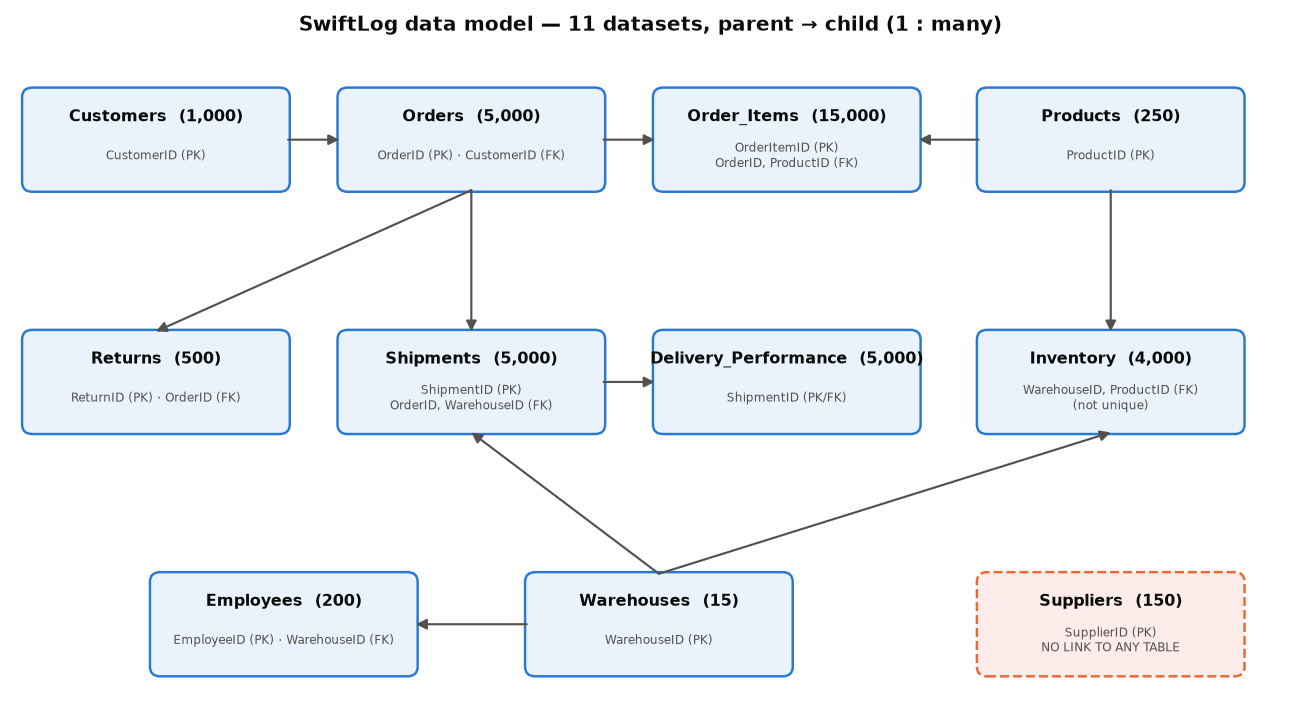

In [7]:
fig, ax = plt.subplots(figsize=(15, 8.2)); ax.set_xlim(0, 15); ax.set_ylim(0, 8.6); ax.axis('off'); ax.grid(False)
pos = {'Customers': (1.7, 7), 'Orders': (5.4, 7), 'Order_Items': (9.1, 7), 'Products': (12.9, 7),
       'Returns': (1.7, 4), 'Shipments': (5.4, 4), 'Delivery_Performance': (9.1, 4), 'Inventory': (12.9, 4),
       'Employees': (3.2, 1), 'Warehouses': (7.6, 1), 'Suppliers': (12.9, 1)}
keys = {'Customers': 'CustomerID (PK)', 'Orders': 'OrderID (PK) · CustomerID (FK)', 'Order_Items': 'OrderItemID (PK)\nOrderID, ProductID (FK)', 'Products': 'ProductID (PK)',
        'Returns': 'ReturnID (PK) · OrderID (FK)', 'Shipments': 'ShipmentID (PK)\nOrderID, WarehouseID (FK)', 'Delivery_Performance': 'ShipmentID (PK/FK)', 'Inventory': 'WarehouseID, ProductID (FK)\n(not unique)',
        'Employees': 'EmployeeID (PK) · WarehouseID (FK)', 'Warehouses': 'WarehouseID (PK)', 'Suppliers': 'SupplierID (PK)\nNO LINK TO ANY TABLE'}
bw, bh = 3.1, 1.25
for t, (x, y) in pos.items():
    dashed = t == 'Suppliers'
    ax.add_patch(FancyBboxPatch((x-bw/2, y-bh/2), bw, bh, boxstyle='round,pad=0.02,rounding_size=0.12', fc='#fdecea' if dashed else '#eaf2fc', ec=ORANGE if dashed else BLUE, lw=1.6, ls='--' if dashed else '-'))
    ax.text(x, y+0.28, f'{t}  ({len(raw[t]):,})', ha='center', va='center', fontsize=10.5, fontweight='bold', color=INK)
    ax.text(x, y-0.2, keys[t], ha='center', va='center', fontsize=8, color='#52514e')
edges = [('Customers','Orders'), ('Orders','Order_Items'), ('Products','Order_Items'), ('Orders','Shipments'), ('Orders','Returns'), ('Shipments','Delivery_Performance'),
         ('Products','Inventory'), ('Warehouses','Inventory'), ('Warehouses','Shipments'), ('Warehouses','Employees')]
def edge_pts(a, b):
    (x1, y1), (x2, y2) = pos[a], pos[b]
    if abs(y1-y2) < .1: s = 1 if x2 > x1 else -1; return (x1+s*bw/2, y1), (x2-s*bw/2, y2)
    if abs(x1-x2) < .1: s = 1 if y2 > y1 else -1; return (x1, y1+s*bh/2), (x2, y2-s*bh/2)
    s = 1 if y2 > y1 else -1; return (x1, y1+s*bh/2), (x2, y2-s*bh/2)
for p, c in edges:
    (a, b) = edge_pts(p, c)
    ax.add_patch(FancyArrowPatch(a, b, arrowstyle='-|>', mutation_scale=14, lw=1.4, color='#52514e', shrinkA=0, shrinkB=0))
ax.text(7.5, 8.35, 'SwiftLog data model — 11 datasets, parent → child (1 : many)', ha='center', fontsize=13, fontweight='bold', color=INK)
chart('01_data_relationship_diagram', 'Data relationship diagram',
      'Orders is the hub: customers, line items, shipments and returns all hang off OrderID. Warehouses connect shipments, stock and staff. Suppliers is isolated.',
      'Operational questions (delivery, returns, customer value) can be joined end-to-end, but supplier performance cannot — SwiftLog must add a SupplierID to Products or Shipments to evaluate suppliers.')

---
# PART 2 — Data Cleaning & Preprocessing
All cleaning lives in **reusable functions** (`standardise_text`, `parse_dates`, `iqr_flag`, `clean_all`, `build_order_master`) so the same pipeline can be re-run on new extracts.
Every action is written to a transformation log (`LOG`) which is displayed at the end of this part.

In [8]:
LOG = []
def log(step, table, action, rows, why): LOG.append(dict(step=len(LOG)+1, table=table, action=action, rows_affected=int(rows), rationale=why))

def standardise_text(df, table, title_cols=(), id_cols=()):
    """Trim + collapse whitespace on all text columns; Title-case categorical columns; upper-case ID columns."""
    df = df.copy(); changed = 0
    for c in df.columns:
        if df[c].dtype == object or str(df[c].dtype).startswith('str'):
            s0 = df[c].astype(str); s = s0.str.strip().str.replace(r'\s+', ' ', regex=True)
            if c in title_cols: s = s.str.title()
            if c in id_cols: s = s.str.upper()
            changed += int((s != s0).sum()); df[c] = s
    log('Standardise text', table, 'trim whitespace, unify case of categorical/ID columns', changed, 'Prevents duplicate categories such as "lagos" vs "Lagos"')
    return df

def parse_dates(df, col, fmt):
    df = df.copy(); df[col] = pd.to_datetime(df[col], format=fmt, errors='coerce')
    bad = int(df[col].isna().sum()); log('Convert data type', 'Orders', f'{col} text → datetime ({fmt})', len(df), f'Unparseable dates: {bad}')
    return df

def iqr_flag(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1; lo, hi = q1 - k*i, q3 + k*i
    return (s < lo) | (s > hi), lo, hi

LOW_STOCK = 20      # assumption: <20 units at a warehouse-product position = low stock (≈4% of the 0-500 range)
def clean_all(raw):
    cl = {}
    cl['Customers'] = standardise_text(raw['Customers'], 'Customers', title_cols=['City'], id_cols=['CustomerID'])
    cl['Products'] = standardise_text(raw['Products'], 'Products', title_cols=['Category'], id_cols=['ProductID'])
    cl['Suppliers'] = standardise_text(raw['Suppliers'], 'Suppliers', id_cols=['SupplierID'])
    cl['Warehouses'] = standardise_text(raw['Warehouses'], 'Warehouses', title_cols=['Location'], id_cols=['WarehouseID'])
    cl['Employees'] = standardise_text(raw['Employees'], 'Employees', id_cols=['EmployeeID', 'WarehouseID'])
    cl['Returns'] = standardise_text(raw['Returns'], 'Returns', title_cols=['Reason'], id_cols=['ReturnID', 'OrderID'])
    # Orders
    o = standardise_text(raw['Orders'], 'Orders', title_cols=['Status'], id_cols=['OrderID', 'CustomerID'])
    o = parse_dates(o, 'OrderDate', '%m/%d/%Y')
    o['Year'], o['Month'], o['Quarter'] = o.OrderDate.dt.year, o.OrderDate.dt.month, o.OrderDate.dt.quarter
    o['MonthName'], o['YearMonth'], o['DayOfWeek'] = o.OrderDate.dt.strftime('%b'), o.OrderDate.dt.strftime('%Y-%m'), o.OrderDate.dt.day_name()
    last = o.OrderDate.max(); o['IsPartialMonth'] = (o.OrderDate.dt.to_period('M') == last.to_period('M')) & (last != last + pd.offsets.MonthEnd(0))
    log('Create date features', 'Orders', 'Year, Month, Quarter, MonthName, YearMonth, DayOfWeek, IsPartialMonth', len(o), f'Last order is {last.date()}, so {last.strftime("%b %Y")} is a partial month and is excluded from trend comparisons')
    cl['Orders'] = o
    # Order items: consolidate repeated (Order, Product) lines, attach price/category
    oi = standardise_text(raw['Order_Items'], 'Order_Items', id_cols=['OrderItemID', 'OrderID', 'ProductID'])
    n_rep = int(oi.duplicated(['OrderID', 'ProductID']).sum())
    oi = oi.groupby(['OrderID', 'ProductID'], as_index=False).agg(OrderItemID=('OrderItemID', 'first'), Quantity=('Quantity', 'sum'), n_merged=('OrderItemID', 'size'))
    log('Consolidate duplicates', 'Order_Items', 'merged repeated (OrderID, ProductID) lines by summing Quantity', n_rep, 'Same product ordered twice in one order = one basket line; avoids double counting basket size')
    oi = oi.merge(cl['Products'][['ProductID', 'Category', 'UnitPrice']], on='ProductID', how='left'); oi['LineValue'] = (oi.Quantity * oi.UnitPrice).round(2)
    log('Create calculated column', 'Order_Items', 'LineValue = Quantity × UnitPrice (joined from Products)', len(oi), 'Revenue is not stored anywhere in the raw data')
    cl['Order_Items'] = oi
    # Inventory: drop exact duplicates, then consolidate duplicate keys as stock lots
    inv = standardise_text(raw['Inventory'], 'Inventory', id_cols=['WarehouseID', 'ProductID'])
    n_ex = int(inv.duplicated().sum()); inv = inv.drop_duplicates(); log('Remove duplicates', 'Inventory', 'dropped exact duplicate rows', n_ex, 'Identical rows are repeated records')
    n_key = int(inv.duplicated(['WarehouseID', 'ProductID']).sum())
    inv = inv.groupby(['WarehouseID', 'ProductID'], as_index=False).agg(Stock=('Stock', 'sum'), n_lots=('Stock', 'size'))
    inv['LowStock'] = inv.Stock < LOW_STOCK
    log('Consolidate duplicates', 'Inventory', 'summed Stock over repeated (WarehouseID, ProductID) keys → n_lots; added LowStock flag (<20)', n_key, 'ASSUMPTION: repeated keys with different quantities are separate stock lots. Sensitivity test below')
    cl['Inventory'] = inv
    # Shipments + delivery performance
    sh = standardise_text(raw['Shipments'], 'Shipments', id_cols=['ShipmentID', 'OrderID', 'WarehouseID'])
    dp = standardise_text(raw['Delivery_Performance'], 'Delivery_Performance', title_cols=['Status'], id_cols=['ShipmentID'])
    sh = sh.merge(dp[['ShipmentID', 'Status']].rename(columns={'Status': 'DeliveryStatus'}), on='ShipmentID', how='left')
    sh['IsDelayed'] = (sh.DelayDays >= 3).astype(int)
    sh['DelaySeverity'] = pd.cut(sh.DelayDays, [-1, 0, 2, 4, 7], labels=['On schedule (0)', 'Minor (1-2)', 'Moderate (3-4)', 'Severe (5-7)']).astype(str)
    mism = int(((sh.IsDelayed == 1) != (sh.DeliveryStatus == 'Delayed')).sum())
    log('Merge + conditional column', 'Shipments', 'joined Delivery_Performance status; IsDelayed = DelayDays ≥ 3; DelaySeverity bands', len(sh), f'Rule verified against the supplied Status field ({mism} mismatches)')
    cl['Shipments'], cl['Delivery_Performance'] = sh, dp
    return cl

def build_order_master(cl):
    o, oi, sh, rt, c, w = cl['Orders'], cl['Order_Items'], cl['Shipments'], cl['Returns'], cl['Customers'], cl['Warehouses']
    g = oi.groupby('OrderID').agg(n_lines=('ProductID', 'size'), units=('Quantity', 'sum'), order_value=('LineValue', 'sum'), n_categories=('Category', 'nunique')).reset_index()
    dom = oi.groupby(['OrderID', 'Category']).LineValue.sum().reset_index().sort_values(['OrderID', 'LineValue'], ascending=[True, False]).drop_duplicates('OrderID')[['OrderID', 'Category']].rename(columns={'Category': 'DominantCategory'})
    r = rt.groupby('OrderID').agg(n_returns=('ReturnID', 'size'), ReturnReasons=('Reason', lambda s: ' | '.join(sorted(s)))).reset_index()
    rd = pd.crosstab(rt.OrderID, rt.Reason).add_prefix('ret_').reset_index()
    m = (o.merge(c[['CustomerID', 'City']].rename(columns={'City': 'CustomerCity'}), on='CustomerID', how='left').merge(g, on='OrderID', how='left').merge(dom, on='OrderID', how='left')
         .merge(sh[['OrderID', 'ShipmentID', 'WarehouseID', 'DelayDays', 'IsDelayed', 'DelaySeverity']], on='OrderID', how='left')
         .merge(w.rename(columns={'Location': 'WarehouseCity'}), on='WarehouseID', how='left').merge(r, on='OrderID', how='left').merge(rd, on='OrderID', how='left'))
    for col in ['n_lines', 'units', 'order_value', 'n_categories', 'n_returns'] + [x for x in m if x.startswith('ret_')]: m[col] = m[col].fillna(0)
    m['HasItems'] = (m.n_lines > 0).astype(int); m['HasReturn'] = (m.n_returns > 0).astype(int)
    m['DominantCategory'] = m.DominantCategory.fillna('No items'); m['ReturnReasons'] = m.ReturnReasons.fillna('')
    m['SameCityDispatch'] = (m.CustomerCity == m.WarehouseCity).astype(int)
    return m

cl = clean_all(raw)
master = build_order_master(cl)
log('Integrate datasets', 'Orders + Customers + Order_Items + Products + Shipments + Warehouses + Returns', 'built the order-level master table (one row per order)', len(master), 'Single analytical grain for EDA, tests and ML features')
print(f'Cleaned tables: {len(cl)} · master table: {master.shape[0]:,} rows × {master.shape[1]} columns')
R['n_orders'] = len(master); R['n_customers_total'] = len(cl['Customers']); R['n_customers_ordering'] = int(master.CustomerID.nunique())
master.head(3).T

Cleaned tables: 11 · master table: 5,000 rows × 31 columns

,0,1,2
OrderID,O00001,O00002,O00003
CustomerID,C0807,C0426,C0810
OrderDate,2026-07-22 00:00:00,2026-04-11 00:00:00,2026-01-07 00:00:00
Status,Delivered,Cancelled,Cancelled
Year,2026,2026,2026
Month,7,4,1
Quarter,3,2,1
MonthName,Jul,Apr,Jan
YearMonth,2026-07,2026-04,2026-01
DayOfWeek,Wednesday,Saturday,Wednesday


In [9]:
# Outlier detection (Tukey 1.5×IQR). Policy: values are VALID business quantities, so they are flagged, never deleted.
oi_c, inv_c, sh_c = cl['Order_Items'], cl['Inventory'], cl['Shipments']
targets = {'Order_Items.Quantity (consolidated)': oi_c.Quantity, 'Products.UnitPrice': cl['Products'].UnitPrice, 'Inventory.Stock (consolidated)': inv_c.Stock,
           'Shipments.DelayDays': sh_c.DelayDays, 'Order_Items.LineValue': oi_c.LineValue, 'Orders.order_value (orders with items)': master.loc[master.HasItems == 1, 'order_value']}
rows = []
for n, s in targets.items():
    f, lo, hi = iqr_flag(s); rows.append(dict(variable=n, n=len(s), lower_fence=lo, upper_fence=hi, outliers=int(f.sum()), outlier_pct=100*f.mean(), max=s.max()))
outl = pd.DataFrame(rows); R['outliers'] = outl.set_index('variable').outliers.to_dict()
# Treatment: keep rows; add a capped copy of order_value (99th pct) for algorithms sensitive to extremes
cap = master.loc[master.HasItems == 1, 'order_value'].quantile(.99); master['order_value_capped'] = master.order_value.clip(upper=cap)
log('Detect & treat outliers', 'All numeric', 'IQR flags; no rows removed; order_value_capped (99th percentile cap) added for modelling', int(outl.outliers.sum()), 'Extreme-but-valid values carry business meaning (large baskets)')
print('Cap used for order_value_capped:', round(cap, 2)); outl

Cap used for order_value_capped: 14090.4

,variable,n,lower_fence,upper_fence,outliers,outlier_pct,max
0,Order_Items.Quantity (consolidated),14904,-4.500,15.500,23,0.154,22.000
1,Products.UnitPrice,250,-227.480,763.080,0,0.000,496.610
2,Inventory.Stock (consolidated),2455,-286.500,"1,029.500",86,3.503,"1,999.000"
3,Shipments.DelayDays,5000,-4.000,12.000,0,0.000,7.000
4,Order_Items.LineValue,14904,"-2,018.700","4,655.700",129,0.866,"7,509.370"
5,Orders.order_value (orders with items),4764,"-3,999.454","12,448.076",106,2.225,"19,290.340"


In [10]:
# Sensitivity of the inventory consolidation assumption: do warehouse stock rankings change if repeated keys are averaged instead of summed?
inv_raw = raw['Inventory'].drop_duplicates()
a = inv_raw.groupby('WarehouseID').Stock.sum(); b = inv_raw.groupby(['WarehouseID', 'ProductID']).Stock.mean().groupby('WarehouseID').sum()
rho = stats.spearmanr(a, b).statistic
R['inv_sensitivity_rho'] = float(rho)
print(f'Spearman rank correlation of warehouse stock ranking, "sum of lots" vs "average of lots": {rho:.3f}')
print('→ Warehouse conclusions are largely stable under the lot-consolidation assumption (rank correlation about 0.8, not identical).' if rho > .8 else '→ Warehouse stock conclusions are sensitive to this assumption; treat with caution.')

Spearman rank correlation of warehouse stock ranking, "sum of lots" vs "average of lots": 0.818
→ Warehouse conclusions are largely stable under the lot-consolidation assumption (rank correlation about 0.8, not identical).

In [11]:
# Save cleaned datasets
out = {'Customers': cl['Customers'], 'Orders': cl['Orders'], 'Order_Items': cl['Order_Items'], 'Products': cl['Products'], 'Suppliers': cl['Suppliers'], 'Warehouses': cl['Warehouses'],
       'Inventory': cl['Inventory'], 'Shipments': cl['Shipments'], 'Delivery_Performance': cl['Delivery_Performance'], 'Employees': cl['Employees'], 'Returns': cl['Returns'], 'Orders_Master': master}
for k, d in out.items(): d.to_csv(CLEAN/f'SwiftLog_{k}_clean.csv', index=False)
print('Saved', len(out), 'cleaned datasets to', CLEAN.relative_to(BASE))
pd.DataFrame(LOG)

Saved 12 cleaned datasets to Data\Cleaned_Datasets

,step,table,action,rows_affected,rationale
0,1,Customers,"trim whitespace, unify case of categorical/ID columns",0,"Prevents duplicate categories such as ""lagos"" vs ""Lagos"""
1,2,Products,"trim whitespace, unify case of categorical/ID columns",0,"Prevents duplicate categories such as ""lagos"" vs ""Lagos"""
2,3,Suppliers,"trim whitespace, unify case of categorical/ID columns",0,"Prevents duplicate categories such as ""lagos"" vs ""Lagos"""
3,4,Warehouses,"trim whitespace, unify case of categorical/ID columns",0,"Prevents duplicate categories such as ""lagos"" vs ""Lagos"""
4,5,Employees,"trim whitespace, unify case of categorical/ID columns",0,"Prevents duplicate categories such as ""lagos"" vs ""Lagos"""
5,6,Returns,"trim whitespace, unify case of categorical/ID columns",0,"Prevents duplicate categories such as ""lagos"" vs ""Lagos"""
6,7,Orders,"trim whitespace, unify case of categorical/ID columns",0,"Prevents duplicate categories such as ""lagos"" vs ""Lagos"""
7,8,Orders,OrderDate text → datetime (%m/%d/%Y),5000,Unparseable dates: 0
8,9,Orders,"Year, Month, Quarter, MonthName, YearMonth, DayOfWeek, IsPartialMonth",5000,"Last order is 2026-09-08, so Sep 2026 is a partial month and is excluded from trend comparisons"
9,10,Order_Items,"trim whitespace, unify case of categorical/ID columns",0,"Prevents duplicate categories such as ""lagos"" vs ""Lagos"""


### Automated data-profiling report
`ydata-profiling` / Sweetviz could not be installed in the build environment (package index blocked), so this notebook generates an equivalent automated profile with pandas + matplotlib
(per-column type, missingness, distinct count, distribution, descriptive statistics, alerts, correlations) → `Reports/Data_Profiling_Report.html`.
If `ydata-profiling` is installed in your environment, the second half of the cell also produces the official report.

In [12]:
def _hist_b64(s, numeric=True):
    fig, ax = plt.subplots(figsize=(3.6, 1.5)); ax.grid(False)
    if numeric: ax.hist(s.dropna(), bins=min(30, max(5, s.nunique())), color=BLUE)
    else: vc = s.value_counts().head(8); ax.barh(vc.index.astype(str)[::-1], vc.values[::-1], color=BLUE)
    ax.tick_params(labelsize=6); [sp.set_visible(False) for sp in ax.spines.values()]
    b = io.BytesIO(); fig.savefig(b, format='png', dpi=80, bbox_inches='tight'); plt.close(fig); return base64.b64encode(b.getvalue()).decode()

def profile_html(tables, path, title):
    css = ('body{font-family:Arial,sans-serif;margin:24px;color:#0b0b0b;background:#fff}h1{color:#16345c}h2{background:#16345c;color:#fff;padding:8px 12px;border-radius:4px;margin-top:34px}'
           '.k{display:inline-block;margin:4px 10px 10px 0;padding:8px 14px;background:#eaf2fc;border-radius:6px}.card{display:inline-block;vertical-align:top;width:380px;margin:6px;padding:10px;border:1px solid #dcdcd8;border-radius:6px;font-size:12px}'
           'table{border-collapse:collapse;font-size:12px}td,th{border:1px solid #dcdcd8;padding:3px 7px;text-align:right}th{background:#f1f1ee}.warn{color:#b3380d}')
    h = [f'<html><head><meta charset="utf-8"><title>{title}</title><style>{css}</style></head><body><h1>{title}</h1>',
         f'<p>Generated {pd.Timestamp.today().date()} by the AnalystLab notebook profiler (pandas + matplotlib). Tables profiled: {len(tables)}.</p>']
    h.append('<h2>Overview</h2><table><tr><th>Table</th><th>Rows</th><th>Cols</th><th>Missing cells</th><th>Duplicate rows</th><th>Memory (KB)</th></tr>')
    for n, d in tables.items(): h.append(f'<tr><td style="text-align:left">{n}</td><td>{len(d):,}</td><td>{d.shape[1]}</td><td>{int(d.isna().sum().sum())}</td><td>{int(d.duplicated().sum())}</td><td>{d.memory_usage(deep=True).sum()/1024:,.0f}</td></tr>')
    h.append('</table>')
    for n, d in tables.items():
        h.append(f'<h2>{n}</h2>'); alerts = []
        for c in d.columns:
            s = d[c]; num = pd.api.types.is_numeric_dtype(s) and s.dtype != bool; nun = s.nunique()
            if nun == len(s) and len(s) > 1: alerts.append(f'{c}: all values unique (identifier)')
            if nun == 1: alerts.append(f'{c}: constant column')
            if num and nun > 2 and abs(stats.skew(s.dropna())) > 1: alerts.append(f'{c}: highly skewed (skew={stats.skew(s.dropna()):.2f})')
            if s.isna().any(): alerts.append(f'{c}: {s.isna().mean():.1%} missing')
            if num and (s == 0).mean() > .3: alerts.append(f'{c}: {(s==0).mean():.0%} zeros')
        h.append('<p class="warn"><b>Alerts:</b> ' + ('; '.join(alerts) if alerts else 'none') + '</p>')
        for c in d.columns:
            s = d[c]; num = pd.api.types.is_numeric_dtype(s) and s.dtype != bool and s.nunique() > 1
            h.append(f'<div class="card"><b>{c}</b> <i>({s.dtype})</i><br>distinct {s.nunique():,} · missing {s.isna().sum()} ({s.isna().mean():.1%})<br>')
            if num: h.append(f'mean {s.mean():,.2f} · median {s.median():,.2f} · std {s.std():,.2f}<br>min {s.min():,.2f} · max {s.max():,.2f} · skew {stats.skew(s.dropna()):.2f} · kurt {stats.kurtosis(s.dropna()):.2f}<br>')
            elif s.nunique() <= 20: h.append('top: ' + ', '.join(f'{k} ({v})' for k, v in s.value_counts().head(5).items()) + '<br>')
            elif not pd.api.types.is_datetime64_any_dtype(s): h.append(f'e.g. {", ".join(map(str, s.head(3)))}<br>')
            if pd.api.types.is_datetime64_any_dtype(s): h.append(f'range {s.min().date()} → {s.max().date()}')
            elif num or 1 < s.nunique() <= 40: h.append(f'<img src="data:image/png;base64,{_hist_b64(s, num)}">')
            h.append('</div>')
    nums = master.select_dtypes('number').loc[:, lambda x: x.nunique() > 1]
    fig, ax = plt.subplots(figsize=(9, 7)); sns.heatmap(nums.corr(), cmap='RdBu_r', center=0, annot=False, ax=ax); ax.set_title('Correlation matrix — Orders_Master (numeric)')
    b = io.BytesIO(); fig.savefig(b, format='png', dpi=90, bbox_inches='tight'); plt.close(fig)
    h.append(f'<h2>Correlations</h2><img src="data:image/png;base64,{base64.b64encode(b.getvalue()).decode()}"></body></html>')
    Path(path).write_text('\n'.join(h), encoding='utf-8')

profile_html(out, REPORTS/'Data_Profiling_Report.html', 'SwiftLog — Automated Data Profiling Report')
print('Wrote', (REPORTS/'Data_Profiling_Report.html').relative_to(BASE), f'({(REPORTS/"Data_Profiling_Report.html").stat().st_size/1e6:.1f} MB)')
try:
    from ydata_profiling import ProfileReport
    ProfileReport(master.drop(columns=['OrderDate']), title='SwiftLog Orders Master', minimal=True).to_file(REPORTS/'Data_Profiling_Report_ydata.html'); print('ydata-profiling report also written.')
except ImportError:
    print('ydata-profiling not installed here — pandas profiler used (install with: pip install ydata-profiling).')

Wrote Reports\Data_Profiling_Report.html (0.4 MB)
ydata-profiling not installed here — pandas profiler used (install with: pip install ydata-profiling).

---
# PART 3 — Exploratory Data Analysis
**Revenue definition.** The raw data has no revenue field and order status is mixed (Delivered / Pending / Cancelled). We therefore report three explicit measures:
*gross value* (all orders), **confirmed value** (all non-cancelled orders — used as the default "revenue" below) and *realised value* (Delivered only).
Unless stated otherwise, currency units are as supplied (the data dictionary does not name the currency).

In [13]:
conf = master[master.Status != 'Cancelled'].copy()
oi_c = cl['Order_Items'].merge(master[['OrderID', 'Status']], on='OrderID')
oi_conf = oi_c[oi_c.Status != 'Cancelled']
emp = cl['Employees'].groupby('WarehouseID').size().rename('employees')
rev = pd.DataFrame({'Gross (all orders)': [master.order_value.sum()], 'Confirmed (excl. Cancelled)': [conf.order_value.sum()], 'Realised (Delivered only)': [master.loc[master.Status == 'Delivered', 'order_value'].sum()]}).T
rev.columns = ['value']; rev['share_of_gross'] = rev.value / rev.value.iloc[0]
R['rev_gross'], R['rev_confirmed'], R['rev_realised'] = [float(v) for v in rev.value]
R['cancel_rate'] = float((master.Status == 'Cancelled').mean()); R['pending_rate'] = float((master.Status == 'Pending').mean()); R['delivered_rate'] = float((master.Status == 'Delivered').mean())
R['cancelled_value'] = float(master.loc[master.Status == 'Cancelled', 'order_value'].sum())
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z*z/n; c = (p + z*z/(2*n)) / d; h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / d; return c-h, c+h
R['delay_rate'] = float(master.IsDelayed.mean()); R['mean_delay'] = float(master.DelayDays.mean()); R['return_rate'] = float(master.HasReturn.mean()); R['n_returns'] = int(len(cl['Returns']))
# sensitivity: does the revenue definition change the product ranking?
def top(df, n=10): return set(df.groupby('ProductID').LineValue.sum().nlargest(n).index)
tg, tc, tr = top(oi_c), top(oi_conf), top(oi_c[oi_c.Status == 'Delivered'])
R['top10_overlap_conf_vs_gross'] = len(tg & tc); R['top10_overlap_conf_vs_delivered'] = len(tr & tc)
print(f"Cancelled orders = {pct(R['cancel_rate'])} of all orders and {short(R['cancelled_value'])} of gross value ({pct(R['cancelled_value']/R['rev_gross'])}).")
print(f"Top-10 product overlap — confirmed vs gross: {R['top10_overlap_conf_vs_gross']}/10 ; confirmed vs delivered-only: {R['top10_overlap_conf_vs_delivered']}/10  → product rankings depend materially on the status filter, so product conclusions carry that caveat.")
rev

Cancelled orders = 32.5% of all orders and 7.23M of gross value (33.4%).
Top-10 product overlap — confirmed vs gross: 6/10 ; confirmed vs delivered-only: 6/10  → product rankings depend materially on the status filter, so product conclusions carry that caveat.

,value,share_of_gross
Gross (all orders),"21,668,065.850",1.000
Confirmed (excl. Cancelled),"14,439,218.220",0.666
Realised (Delivered only),"7,107,470.530",0.328


## 3.1 Univariate analysis — Customers, Orders, Products, Inventory, Shipments, Returns, Suppliers, Warehouses

Chart 2 · Customers by city
  Interpretation: Customers split almost evenly across four cities (Ibadan largest at 26.2%, Abuja smallest at 23.9%).
  Business implication: Demand is geographically balanced, so no single city dominates planning — but Ibadan holds the largest customer base yet has no SwiftLog warehouse (all Ibadan orders are dispatched from another city).

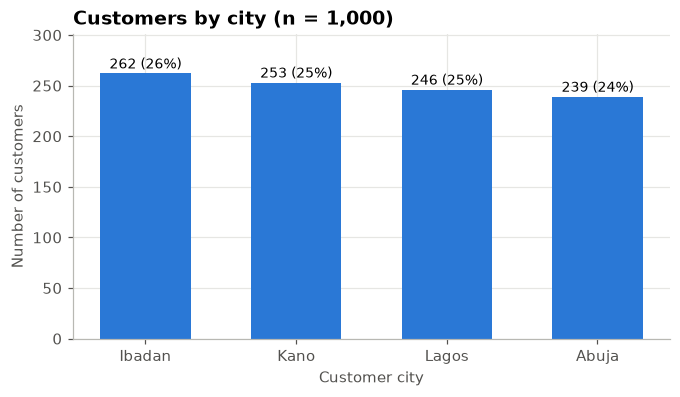

In [14]:
cc = cl['Customers'].City.value_counts()
fig, ax = plt.subplots(figsize=(7, 3.6)); ax.bar(cc.index, cc.values, color=BLUE, width=.6)
for i, v in enumerate(cc.values): ax.text(i, v + 5, f'{v} ({pct(v/cc.sum(),0)})', ha='center', fontsize=9)
ax.set_title('Customers by city (n = 1,000)'); ax.set_ylabel('Number of customers'); ax.set_xlabel('Customer city'); ax.set_ylim(0, cc.max()*1.15)
chart('02_customers_by_city', 'Customers by city', f"Customers split almost evenly across four cities ({cc.index[0]} largest at {pct(cc.iloc[0]/cc.sum())}, {cc.index[-1]} smallest at {pct(cc.iloc[-1]/cc.sum())}).",
      'Demand is geographically balanced, so no single city dominates planning — but Ibadan holds the largest customer base yet has no SwiftLog warehouse (all Ibadan orders are dispatched from another city).')

Chart 3 · Monthly orders by status
  Interpretation: Order volume is steady at roughly 606 orders a month (range 577–654; peak 2026-08, low 2026-02). In every month about a third of orders are Cancelled and a third are still Pending.
  Business implication: Only 33.2% of orders are Delivered while 32.5% are Cancelled — a persistent conversion leak worth 7.23M in order value. Fixing cancellations is a bigger lever than adding demand.

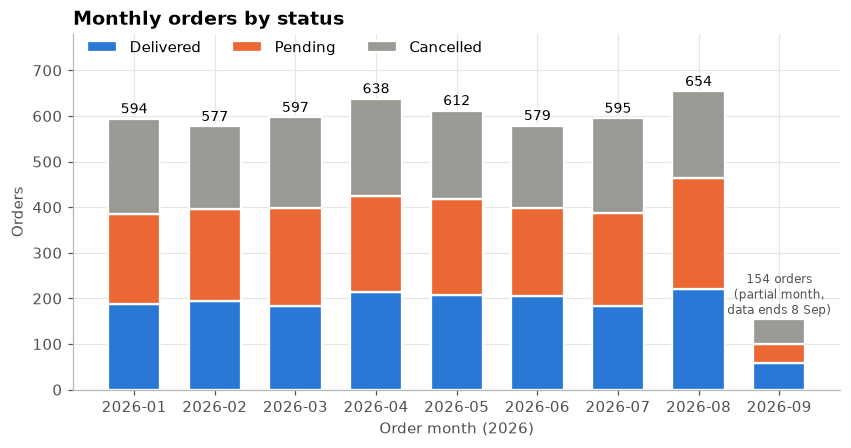

In [15]:
ms = master.groupby(['YearMonth', 'Status']).size().unstack(fill_value=0)[['Delivered', 'Pending', 'Cancelled']]
fig, ax = plt.subplots(figsize=(9, 4.2)); bottom = np.zeros(len(ms)); cols = {'Delivered': BLUE, 'Pending': ORANGE, 'Cancelled': GREY}
for s in ms.columns:
    bars = ax.bar(ms.index, ms[s], bottom=bottom, color=cols[s], label=s, width=.65, edgecolor='white', linewidth=1.5); bottom += ms[s].values
bars = ax.patches[-1]; ax.text(len(ms)-1, bottom[-1] + 12, '154 orders\n(partial month,\ndata ends 8 Sep)', ha='center', fontsize=8, color='#52514e')
for i, v in enumerate(bottom[:-1]): ax.text(i, v + 12, f'{int(v)}', ha='center', fontsize=9)
ax.set_title('Monthly orders by status'); ax.set_ylabel('Orders'); ax.set_xlabel('Order month (2026)'); ax.legend(ncol=3, loc='upper left', bbox_to_anchor=(0, 1.02)); ax.set_ylim(0, 780)
full = ms.iloc[:-1].sum(axis=1); R['peak_month'] = full.idxmax(); R['peak_month_orders'] = int(full.max()); R['low_month'] = full.idxmin(); R['low_month_orders'] = int(full.min()); R['monthly_orders'] = full.to_dict()
chart('03_monthly_orders_by_status', 'Monthly orders by status', f"Order volume is steady at roughly {full.mean():.0f} orders a month (range {full.min()}–{full.max()}; peak {R['peak_month']}, low {R['low_month']}). In every month about a third of orders are Cancelled and a third are still Pending.",
      f"Only {pct(R['delivered_rate'])} of orders are Delivered while {pct(R['cancel_rate'])} are Cancelled — a persistent conversion leak worth {short(R['cancelled_value'])} in order value. Fixing cancellations is a bigger lever than adding demand.")

Chart 4 · Unit price by category
  Interpretation: All three categories span the full price range (≈12–497) with similar medians (251–297); category is not a proxy for price tier.
  Business implication: Pricing is not differentiated by category, so category-level revenue differences come from volume and mix, not premium pricing — a pricing-strategy opportunity (premium vs value tiers).

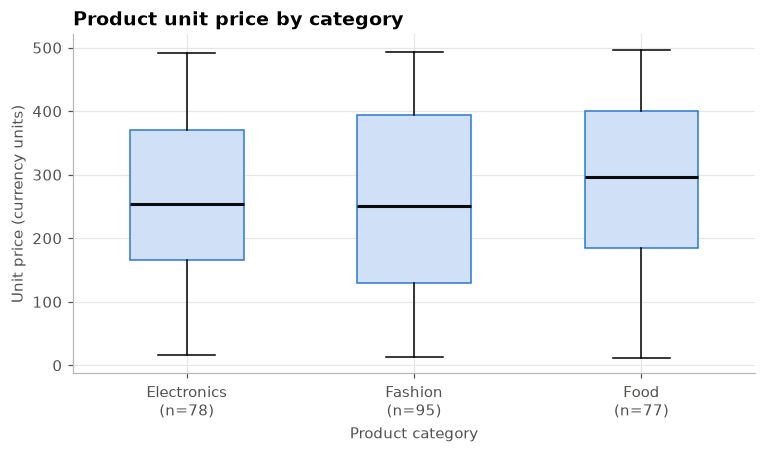

In [16]:
fig, ax = plt.subplots(figsize=(8, 4)); order = ['Electronics', 'Fashion', 'Food']; data = [cl['Products'].loc[cl['Products'].Category == c, 'UnitPrice'] for c in order]
bp = ax.boxplot(data, tick_labels=[f'{c}\n(n={len(d)})' for c, d in zip(order, data)], patch_artist=True, widths=.5, medianprops=dict(color=INK, lw=2))
for p in bp['boxes']: p.set(facecolor='#cfe0f7', edgecolor=BLUE)
ax.set_title('Product unit price by category'); ax.set_ylabel('Unit price (currency units)'); ax.set_xlabel('Product category')
pm = cl['Products'].groupby('Category').UnitPrice.agg(['mean', 'median', 'std']); R['price_by_cat'] = pm.round(2).to_dict()
chart('04_price_by_category', 'Unit price by category', f"All three categories span the full price range (≈{cl['Products'].UnitPrice.min():.0f}–{cl['Products'].UnitPrice.max():.0f}) with similar medians ({pm['median'].min():.0f}–{pm['median'].max():.0f}); category is not a proxy for price tier.",
      'Pricing is not differentiated by category, so category-level revenue differences come from volume and mix, not premium pricing — a pricing-strategy opportunity (premium vs value tiers).')

Chart 5 · Stock distribution
  Interpretation: Stock per position is spread broadly (median 364 units); only 54 of 2,455 positions (2.2%) fall below 20 units, 3 are at zero.
  Business implication: Stock-outs are rare overall but not absent: the few low/zero positions are concentrated and can be fixed with targeted replenishment rather than a blanket stock increase. The long right tail comes from consolidated stock lots.

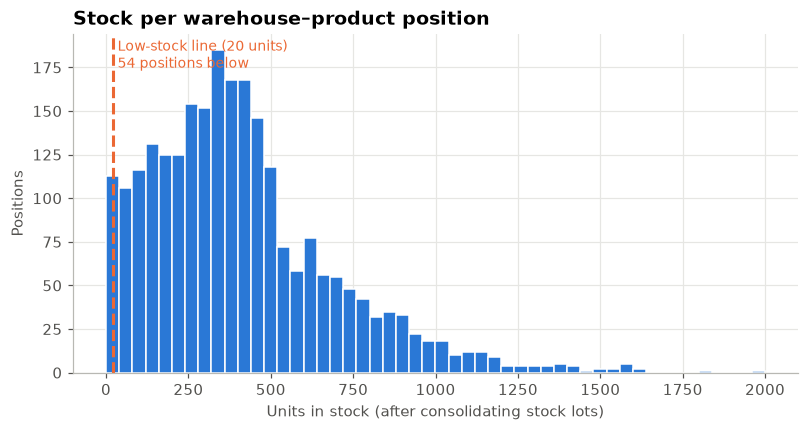

In [17]:
fig, ax = plt.subplots(figsize=(8.5, 4)); ax.hist(inv_c.Stock, bins=50, color=BLUE, edgecolor='white'); ax.axvline(LOW_STOCK, color=ORANGE, lw=2, ls='--')
ax.text(LOW_STOCK + 15, ax.get_ylim()[1]*.9, f'Low-stock line ({LOW_STOCK} units)\n{int(inv_c.LowStock.sum())} positions below', color=ORANGE, fontsize=9)
ax.set_title('Stock per warehouse–product position'); ax.set_xlabel('Units in stock (after consolidating stock lots)'); ax.set_ylabel('Positions')
R['low_stock_positions'] = int(inv_c.LowStock.sum()); R['zero_stock_positions'] = int((inv_c.Stock == 0).sum()); R['inv_positions'] = len(inv_c); R['total_stock'] = int(inv_c.Stock.sum())
chart('05_stock_distribution', 'Stock distribution', f"Stock per position is spread broadly (median {inv_c.Stock.median():.0f} units); only {R['low_stock_positions']} of {R['inv_positions']:,} positions ({pct(R['low_stock_positions']/R['inv_positions'])}) fall below {LOW_STOCK} units, {R['zero_stock_positions']} are at zero.",
      'Stock-outs are rare overall but not absent: the few low/zero positions are concentrated and can be fixed with targeted replenishment rather than a blanket stock increase. The long right tail comes from consolidated stock lots.')

Chart 6 · Distribution of shipment delay
  Interpretation: Delays are spread almost uniformly from 0 to 7 days (no peak at zero). 63.7% of shipments are 'Delayed' (≥3 days); the mean delay is 3.57 days.
  Business implication: A uniform spread means lateness is systemic, not the result of a few bad events: fewer than 4 in 10 shipments are on time. Delivery reliability needs a network-wide process fix, not firefighting.

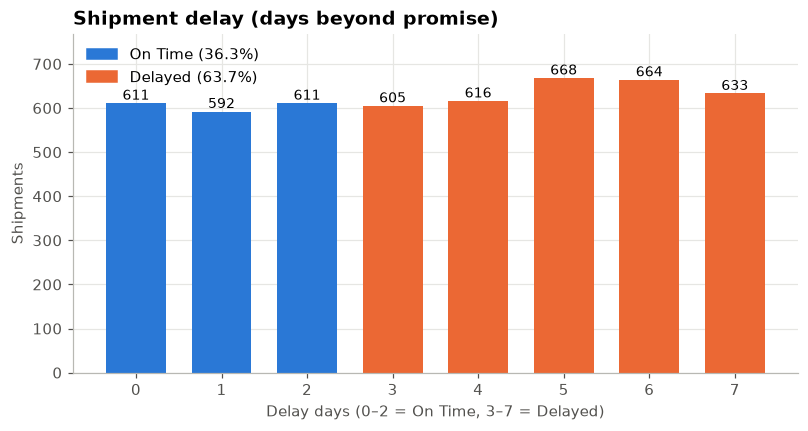

In [18]:
dc = master.DelayDays.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8.5, 4)); ax.bar(dc.index, dc.values, color=[BLUE if d <= 2 else ORANGE for d in dc.index], width=.7)
for d, v in dc.items(): ax.text(d, v + 8, f'{v}', ha='center', fontsize=9)
ax.set_title('Shipment delay (days beyond promise)'); ax.set_xlabel('Delay days (0–2 = On Time, 3–7 = Delayed)'); ax.set_ylabel('Shipments'); ax.set_ylim(0, dc.max()*1.15)
ax.legend(handles=[mpatches.Patch(color=BLUE, label=f'On Time ({pct(1-R["delay_rate"])})'), mpatches.Patch(color=ORANGE, label=f'Delayed ({pct(R["delay_rate"])})')], loc='upper left')
chart('06_delay_distribution', 'Distribution of shipment delay', f"Delays are spread almost uniformly from 0 to 7 days (no peak at zero). {pct(R['delay_rate'])} of shipments are 'Delayed' (≥3 days); the mean delay is {R['mean_delay']:.2f} days.",
      'A uniform spread means lateness is systemic, not the result of a few bad events: fewer than 4 in 10 shipments are on time. Delivery reliability needs a network-wide process fix, not firefighting.')

Chart 7 · Return reasons
  Interpretation: Late Delivery is the most frequent reason (37.0%), followed by Wrong Item (32.6%) and Damaged (30.4%); 9.5% of orders have at least one return.
  Business implication: Roughly two-thirds of returns are controllable by operations (wrong item = picking accuracy; damaged = handling/packaging) rather than customer preference, so returns can be cut through warehouse process quality.

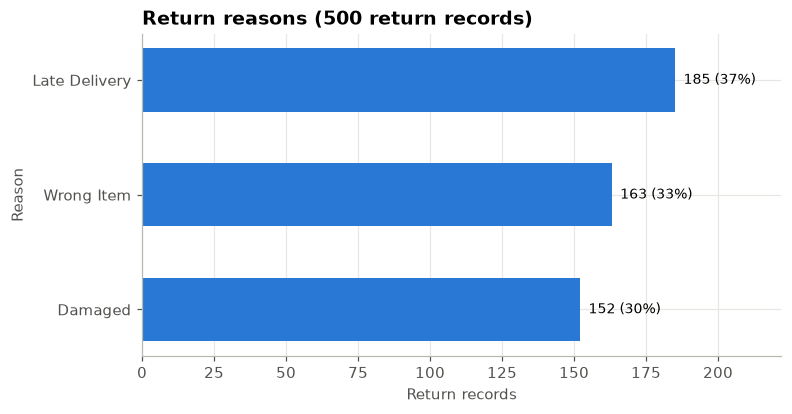

In [19]:
rc = cl['Returns'].Reason.value_counts()
fig, ax = plt.subplots(figsize=(7.5, 3.8)); ax.barh(rc.index[::-1], rc.values[::-1], color=BLUE, height=.55)
for i, v in enumerate(rc.values[::-1]): ax.text(v + 3, i, f'{v} ({pct(v/rc.sum(),0)})', va='center', fontsize=9)
ax.set_title(f'Return reasons ({len(cl["Returns"])} return records)'); ax.set_xlabel('Return records'); ax.set_ylabel('Reason'); ax.set_xlim(0, rc.max()*1.2)
R['return_reasons'] = rc.to_dict()
chart('07_return_reasons', 'Return reasons', f"{rc.index[0]} is the most frequent reason ({pct(rc.iloc[0]/rc.sum())}), followed by {rc.index[1]} ({pct(rc.iloc[1]/rc.sum())}) and {rc.index[2]} ({pct(rc.iloc[2]/rc.sum())}); {pct(R['return_rate'])} of orders have at least one return.",
      'Roughly two-thirds of returns are controllable by operations (wrong item = picking accuracy; damaged = handling/packaging) rather than customer preference, so returns can be cut through warehouse process quality.')

Chart 8 · Warehouse workload per employee
  Interpretation: Shipments handled per employee range from 20 (W13) to 38 (W14) — a 1.9× spread. Heaviest loads: W14, W15, W12.
  Business implication: Staffing is not aligned with workload: shipment volume is nearly equal across warehouses (≈280–370) but headcount varies 9–17. Rebalancing staff toward the overloaded sites is a low-cost capacity gain. (Warehouse capacity is not in the data, so this is a load proxy, not utilisation.)

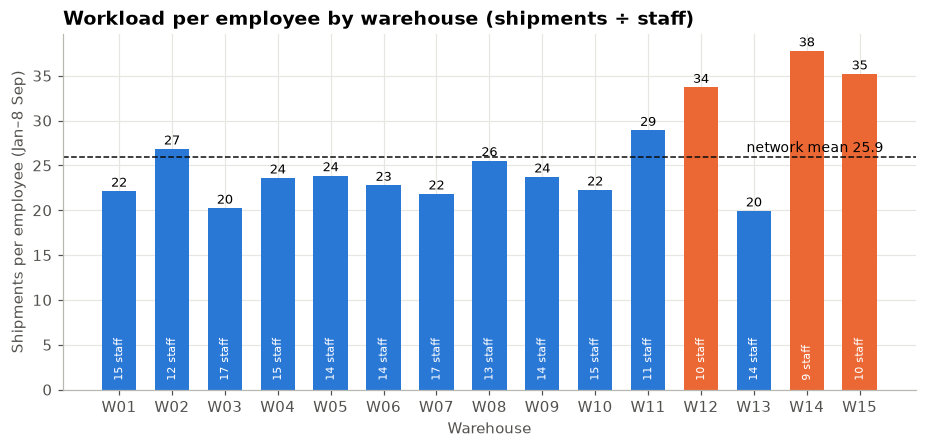

In [20]:
wl = pd.DataFrame({'shipments': master.groupby('WarehouseID').size(), 'city': cl['Warehouses'].set_index('WarehouseID').Location}).join(emp); wl['ship_per_emp'] = wl.shipments / wl.employees
R['wh_load'] = wl.round(2).to_dict('index'); R['load_ratio'] = float(wl.ship_per_emp.max() / wl.ship_per_emp.min())
fig, ax = plt.subplots(figsize=(10, 4.2)); colr = [ORANGE if v > wl.ship_per_emp.mean()*1.25 else BLUE for v in wl.ship_per_emp]; ax.bar(wl.index, wl.ship_per_emp, color=colr, width=.65)
ax.axhline(wl.ship_per_emp.mean(), color=INK, ls='--', lw=1); ax.text(14.45, wl.ship_per_emp.mean() + .6, f'network mean {wl.ship_per_emp.mean():.1f}', ha='right', fontsize=9)
for i, (w, r) in enumerate(wl.iterrows()): ax.text(i, r.ship_per_emp + .5, f'{r.ship_per_emp:.0f}', ha='center', fontsize=8.5); ax.text(i, 1, f'{int(r.employees)} staff', ha='center', fontsize=7.5, color='white', rotation=90, va='bottom')
ax.set_title('Workload per employee by warehouse (shipments ÷ staff)'); ax.set_xlabel('Warehouse'); ax.set_ylabel('Shipments per employee (Jan–8 Sep)')
hi = wl.sort_values('ship_per_emp').index[-3:][::-1].tolist(); lo = wl.ship_per_emp.idxmin()
chart('08_workload_per_employee', 'Warehouse workload per employee', f"Shipments handled per employee range from {wl.ship_per_emp.min():.0f} ({lo}) to {wl.ship_per_emp.max():.0f} ({wl.ship_per_emp.idxmax()}) — a {R['load_ratio']:.1f}× spread. Heaviest loads: {', '.join(hi)}.",
      'Staffing is not aligned with workload: shipment volume is nearly equal across warehouses (≈280–370) but headcount varies 9–17. Rebalancing staff toward the overloaded sites is a low-cost capacity gain. (Warehouse capacity is not in the data, so this is a load proxy, not utilisation.)')

Chart 9 · Order value and basket size
  Interpretation: Order value is right-skewed (mean 4,548 > median 3,949; skew 0.99); a typical basket is 16 units across 3 products.
  Business implication: Baskets are large for a logistics catalogue, and 236 orders (4.7%) carry no line items at all — an order-capture defect that hides revenue and should be closed at source.

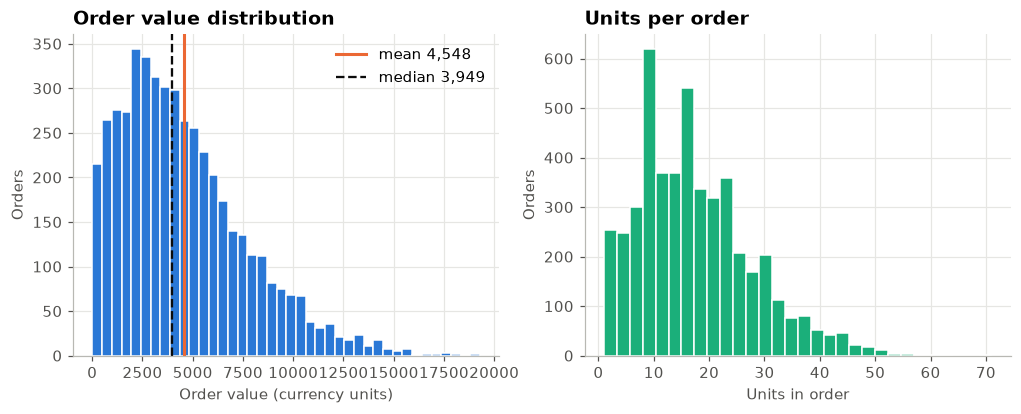

In [21]:
ov = master.loc[master.HasItems == 1, 'order_value']
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8)); axs[0].hist(ov, bins=40, color=BLUE, edgecolor='white'); axs[0].axvline(ov.mean(), color=ORANGE, lw=2); axs[0].axvline(ov.median(), color=INK, lw=1.5, ls='--')
axs[0].set_title('Order value distribution'); axs[0].set_xlabel('Order value (currency units)'); axs[0].set_ylabel('Orders'); axs[0].legend(['mean ' + short(ov.mean()), 'median ' + short(ov.median())], loc='upper right')
axs[1].hist(master.loc[master.HasItems == 1, 'units'], bins=30, color=AQUA, edgecolor='white'); axs[1].set_title('Units per order'); axs[1].set_xlabel('Units in order'); axs[1].set_ylabel('Orders')
R['aov_all'] = float(ov.mean()); R['aov_conf'] = float(conf.loc[conf.HasItems == 1, 'order_value'].mean()); R['orders_no_items'] = int((master.HasItems == 0).sum())
chart('09_order_value_distribution', 'Order value and basket size', f"Order value is right-skewed (mean {short(ov.mean())} > median {short(ov.median())}; skew {stats.skew(ov):.2f}); a typical basket is {master.loc[master.HasItems==1,'units'].median():.0f} units across {master.loc[master.HasItems==1,'n_lines'].median():.0f} products.",
      f"Baskets are large for a logistics catalogue, and {R['orders_no_items']} orders ({pct(R['orders_no_items']/len(master))}) carry no line items at all — an order-capture defect that hides revenue and should be closed at source.")

In [22]:
sup = cl['Suppliers']
print(f"Suppliers: {len(sup)} IDs (S001–S150) with a name column only ('Supplier 1' … 'Supplier 150'). No supplier attribute, no region, no category and — critically — no SupplierID on Products, Inventory or Shipments.")
print('Univariate analysis of suppliers is therefore limited to counting them. Supplier performance, reliability and segmentation CANNOT be computed from this dataset;')
print('Part 5 substitutes a Warehouse Reliability Score and Part 7 states this as a data gap with a concrete fix.')
R['n_suppliers'] = len(sup)

Suppliers: 150 IDs (S001–S150) with a name column only ('Supplier 1' … 'Supplier 150'). No supplier attribute, no region, no category and — critically — no SupplierID on Products, Inventory or Shipments.
Univariate analysis of suppliers is therefore limited to counting them. Supplier performance, reliability and segmentation CANNOT be computed from this dataset;
Part 5 substitutes a Warehouse Reliability Score and Part 7 states this as a data gap with a concrete fix.

## 3.2 Bivariate analysis

Chart 10 · Customer order frequency and revenue concentration
  Interpretation: Customers place 5.0 orders on average (max 15); 9 customers never ordered. Revenue is only mildly concentrated: the top 20% of customers deliver 41.0% of confirmed revenue (Gini 0.38; the Pareto 80/20 rule does not hold).
  Business implication: There is no small group of "whales" to protect — value comes from a broad, evenly-spread base. Retention and frequency programmes across the whole base will matter more than key-account management.

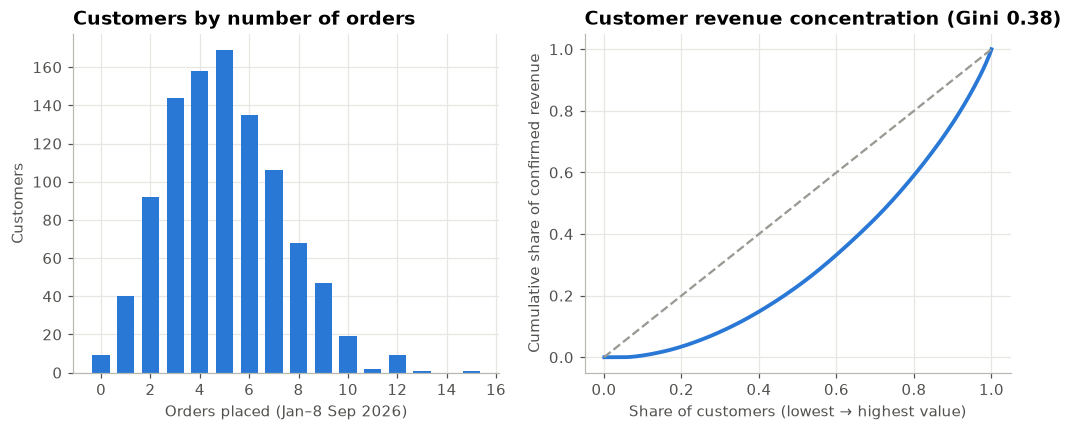

In [23]:
cust = master.groupby('CustomerID').agg(orders=('OrderID', 'size')).reindex(cl['Customers'].CustomerID, fill_value=0)
cv = conf.groupby('CustomerID').order_value.sum().reindex(cl['Customers'].CustomerID, fill_value=0).sort_values()
lor = np.cumsum(cv.values) / cv.sum(); x = np.arange(1, len(cv)+1) / len(cv); gini = 1 - 2*np.trapezoid(lor, x)
fig, axs = plt.subplots(1, 2, figsize=(11, 4)); vc = cust.orders.value_counts().sort_index(); axs[0].bar(vc.index, vc.values, color=BLUE, width=.7)
axs[0].set_title('Customers by number of orders'); axs[0].set_xlabel('Orders placed (Jan–8 Sep 2026)'); axs[0].set_ylabel('Customers')
axs[1].plot(x, lor, color=BLUE, lw=2.5); axs[1].plot([0, 1], [0, 1], color=GREY, ls='--'); axs[1].set_title(f'Customer revenue concentration (Gini {gini:.2f})'); axs[1].set_xlabel('Share of customers (lowest → highest value)'); axs[1].set_ylabel('Cumulative share of confirmed revenue')
top20 = cv.sort_values(ascending=False).head(int(.2*len(cv))).sum() / cv.sum(); R['cust_gini'] = float(gini); R['cust_top20_share'] = float(top20); R['orders_per_cust_mean'] = float(cust.orders.mean()); R['cust_zero_orders'] = int((cust.orders == 0).sum())
chart('10_customer_orders_concentration', 'Customer order frequency and revenue concentration', f"Customers place {cust.orders.mean():.1f} orders on average (max {cust.orders.max()}); {R['cust_zero_orders']} customers never ordered. Revenue is only mildly concentrated: the top 20% of customers deliver {pct(top20)} of confirmed revenue (Gini {gini:.2f}; the Pareto 80/20 rule does not hold).",
      'There is no small group of "whales" to protect — value comes from a broad, evenly-spread base. Retention and frequency programmes across the whole base will matter more than key-account management.')

Chart 11 · Top 10 customers
  Interpretation: The top customer (C0223) generated 58.7K; together the top 10 account for only 3.3% of confirmed revenue.
  Business implication: Even SwiftLog's best customers are individually small, which limits single-customer risk but also means growth must come from the base, not a few accounts. Use these 10 as a pilot group for loyalty and service-level offers.

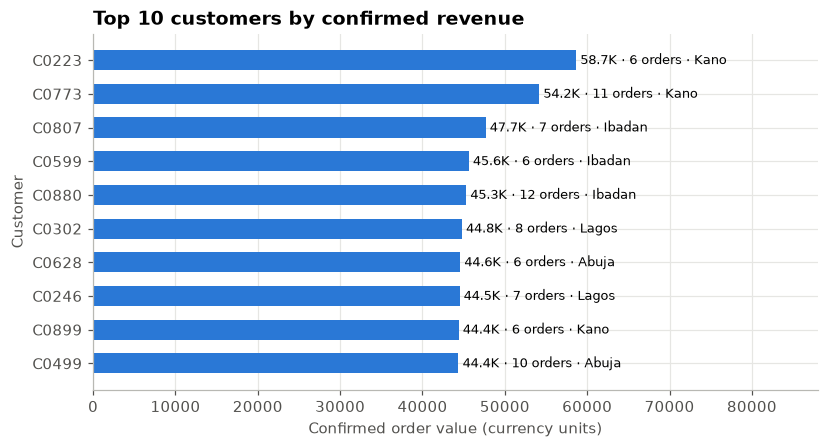

In [24]:
tc_ = conf.groupby('CustomerID').agg(rev=('order_value', 'sum'), orders=('OrderID', 'size'), city=('CustomerCity', 'first')).sort_values('rev', ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8.5, 4.2)); ax.barh(tc_.index[::-1], tc_.rev[::-1], color=BLUE, height=.6)
for i, (c, r) in enumerate(tc_[::-1].iterrows()): ax.text(r.rev + 500, i, f'{short(r.rev)} · {int(r.orders)} orders · {r.city}', va='center', fontsize=8.5)
ax.set_title('Top 10 customers by confirmed revenue'); ax.set_xlabel('Confirmed order value (currency units)'); ax.set_ylabel('Customer'); ax.set_xlim(0, tc_.rev.max()*1.5)
R['top_customers'] = [dict(customer=c, revenue=float(r.rev), orders=int(r.orders), city=r.city) for c, r in tc_.iterrows()]; R['top10_cust_share'] = float(tc_.rev.sum() / conf.order_value.sum())
chart('11_top_customers', 'Top 10 customers', f"The top customer ({tc_.index[0]}) generated {short(tc_.rev.iloc[0])}; together the top 10 account for only {pct(R['top10_cust_share'])} of confirmed revenue.",
      'Even SwiftLog\'s best customers are individually small, which limits single-customer risk but also means growth must come from the base, not a few accounts. Use these 10 as a pilot group for loyalty and service-level offers.')

Chart 12 · Category vs revenue
  Interpretation: Fashion leads with 37.5% of confirmed revenue (5.41M), then Food (32.8%) and Electronics (29.7%). On a per-product basis Food is strongest.
  Business implication: Fashion leads partly because it has the most SKUs (95 vs 77–78); on a per-SKU basis Food is the most productive range. Range-extension decisions should use revenue per SKU, not total revenue.

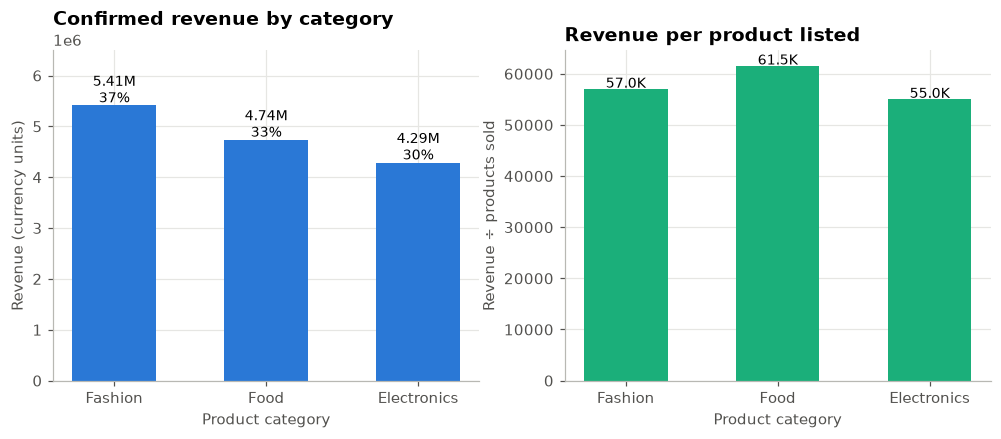

In [25]:
cat = oi_conf.groupby('Category').agg(revenue=('LineValue', 'sum'), units=('Quantity', 'sum'), products=('ProductID', 'nunique')).assign(share=lambda d: d.revenue/d.revenue.sum()); cat['rev_per_product'] = cat.revenue / cat.products
cat = cat.sort_values('revenue', ascending=False); R['category_revenue'] = cat.round(3).to_dict('index')
fig, axs = plt.subplots(1, 2, figsize=(11, 3.9)); axs[0].bar(cat.index, cat.revenue, color=BLUE, width=.55)
for i, (c, r) in enumerate(cat.iterrows()): axs[0].text(i, r.revenue + 6e4, f'{short(r.revenue)}\n{pct(r.share,0)}', ha='center', fontsize=9)
axs[0].set_title('Confirmed revenue by category'); axs[0].set_ylabel('Revenue (currency units)'); axs[0].set_xlabel('Product category'); axs[0].set_ylim(0, cat.revenue.max()*1.2)
axs[1].bar(cat.index, cat.rev_per_product, color=AQUA, width=.55); axs[1].set_title('Revenue per product listed'); axs[1].set_ylabel('Revenue ÷ products sold'); axs[1].set_xlabel('Product category')
for i, v in enumerate(cat.rev_per_product): axs[1].text(i, v + 300, short(v), ha='center', fontsize=9)
chart('12_category_revenue', 'Category vs revenue', f"{cat.index[0]} leads with {pct(cat.share.iloc[0])} of confirmed revenue ({short(cat.revenue.iloc[0])}), then {cat.index[1]} ({pct(cat.share.iloc[1])}) and {cat.index[2]} ({pct(cat.share.iloc[2])}). On a per-product basis {cat.rev_per_product.idxmax()} is strongest.",
      f"Fashion leads partly because it has the most SKUs (95 vs 77–78); on a per-SKU basis {cat.rev_per_product.idxmax()} is the most productive range. Range-extension decisions should use revenue per SKU, not total revenue.")

Chart 13 · Product Pareto curve
  Interpretation: Revenue is spread thinly across the catalogue: the top 20% of products generate only 36.0% of revenue, and 145 of 250 products (58%) are needed to reach 80%.
  Business implication: The catalogue has no "hero" products and no obvious tail to cut. Best-seller lists (e.g. P085, P040, P025) are only marginally ahead, so range-rationalisation should be based on margin and return data, not revenue rank alone.

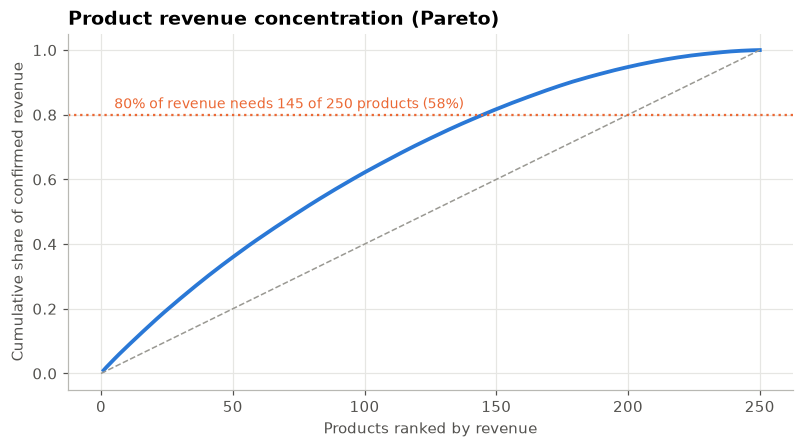

In [26]:
pr = oi_conf.groupby('ProductID').LineValue.sum().sort_values(ascending=False); cum = pr.cumsum() / pr.sum()
n80 = int((cum < .8).sum() + 1); share20 = pr.head(int(.2*len(pr))).sum() / pr.sum()
fig, ax = plt.subplots(figsize=(8.5, 4.2)); ax.plot(np.arange(1, len(cum)+1), cum.values, color=BLUE, lw=2.5); ax.plot([0, len(cum)], [0, 1], color=GREY, ls='--', lw=1)
ax.axhline(.8, color=ORANGE, ls=':'); ax.text(5, .82, f'80% of revenue needs {n80} of {len(pr)} products ({pct(n80/len(pr),0)})', color=ORANGE, fontsize=9)
ax.set_title('Product revenue concentration (Pareto)'); ax.set_xlabel('Products ranked by revenue'); ax.set_ylabel('Cumulative share of confirmed revenue')
R['products_for_80'] = n80; R['top20pct_products_share'] = float(share20); R['top_products'] = [dict(product=p, revenue=float(v), category=cl['Products'].set_index('ProductID').Category[p]) for p, v in pr.head(10).items()]
chart('13_product_pareto', 'Product Pareto curve', f"Revenue is spread thinly across the catalogue: the top 20% of products generate only {pct(share20)} of revenue, and {n80} of {len(pr)} products ({pct(n80/len(pr),0)}) are needed to reach 80%.",
      'The catalogue has no "hero" products and no obvious tail to cut. Best-seller lists (e.g. ' + ', '.join(pr.index[:3]) + ') are only marginally ahead, so range-rationalisation should be based on margin and return data, not revenue rank alone.')

Chart 14 · Warehouse vs inventory levels
  Interpretation: Stock held ranges from 56.5K (W01) to 77.5K (W12) units. Low-stock positions cluster in W14, W06, W13 (20 of 54).
  Business implication: Low-stock positions are concentrated in a handful of warehouses (a few sites hold over a third of them), so replenishment should be targeted there first rather than raised network-wide.

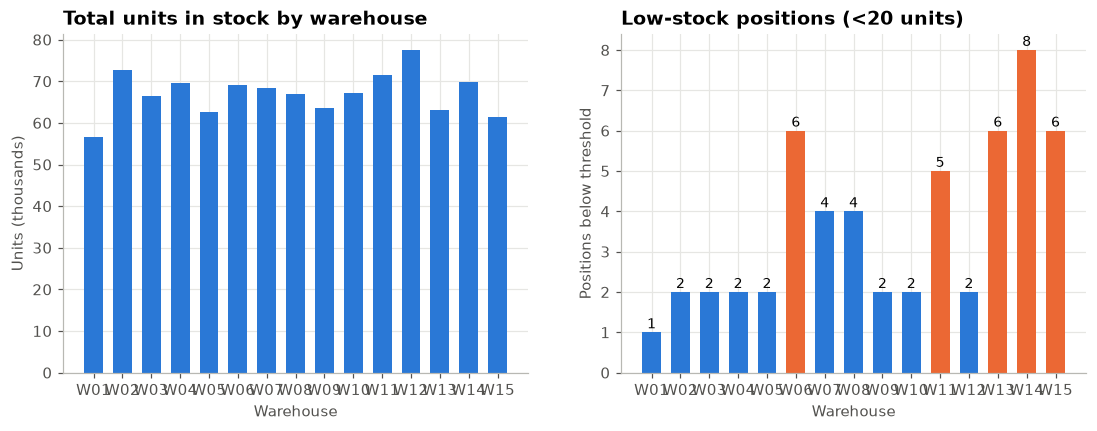

In [27]:
wi = inv_c.groupby('WarehouseID').agg(stock=('Stock', 'sum'), low=('LowStock', 'sum'), positions=('ProductID', 'size')).join(emp); wi['stock_per_emp'] = wi.stock / wi.employees
R['wh_inventory'] = wi.round(2).to_dict('index')
fig, axs = plt.subplots(1, 2, figsize=(12, 4)); axs[0].bar(wi.index, wi.stock/1000, color=BLUE, width=.65); axs[0].set_title('Total units in stock by warehouse'); axs[0].set_xlabel('Warehouse'); axs[0].set_ylabel('Units (thousands)')
axs[1].bar(wi.index, wi.low, color=[ORANGE if v >= 5 else BLUE for v in wi.low], width=.65)
for i, v in enumerate(wi.low): axs[1].text(i, v + .1, int(v), ha='center', fontsize=9)
axs[1].set_title(f'Low-stock positions (<{LOW_STOCK} units)'); axs[1].set_xlabel('Warehouse'); axs[1].set_ylabel('Positions below threshold')
worst = wi.low.nlargest(3).index.tolist(); R['low_stock_worst'] = worst
chart('14_warehouse_inventory', 'Warehouse vs inventory levels', f"Stock held ranges from {short(wi.stock.min())} ({wi.stock.idxmin()}) to {short(wi.stock.max())} ({wi.stock.idxmax()}) units. Low-stock positions cluster in {', '.join(worst)} ({int(wi.low[worst].sum())} of {int(wi.low.sum())}).",
      'Low-stock positions are concentrated in a handful of warehouses (a few sites hold over a third of them), so replenishment should be targeted there first rather than raised network-wide.')

Chart 15 · Delivery performance by warehouse
  Interpretation: Delay rates run from 58.7% (W01) to 68.0% (W05), but every warehouse's confidence interval overlaps the network average of 63.7% (χ² p = 0.33).
  Business implication: Warehouse-to-warehouse differences are statistically indistinguishable from chance. Management should NOT single out a "bad" warehouse; the delay problem is network-wide and points to a shared upstream cause (carrier SLAs, dispatch planning or the promise-date rule).

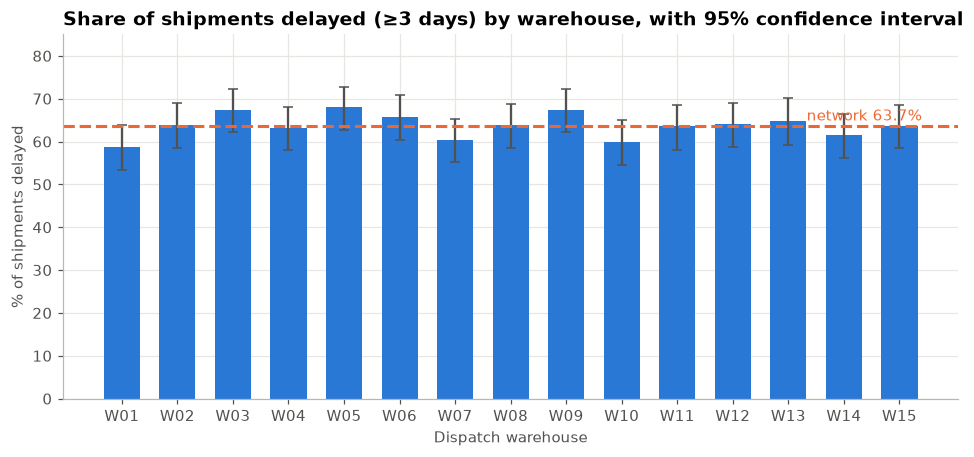

In [28]:
dw = master.groupby('WarehouseID').agg(n=('OrderID', 'size'), late=('IsDelayed', 'sum'), md=('DelayDays', 'mean')); dw['rate'] = dw.late / dw.n
ci = np.array([wilson(k, n) for k, n in zip(dw.late, dw.n)]); net = master.IsDelayed.mean()
chi_w = stats.chi2_contingency(pd.crosstab(master.WarehouseID, master.IsDelayed))[1]; R['p_delay_wh'] = float(chi_w); R['wh_delay'] = dw.round(4).to_dict('index')
fig, ax = plt.subplots(figsize=(10.5, 4.3)); ax.bar(dw.index, dw.rate*100, color=BLUE, width=.65, yerr=[(dw.rate-ci[:, 0])*100, (ci[:, 1]-dw.rate)*100], ecolor='#52514e', capsize=3)
ax.axhline(net*100, color=ORANGE, lw=2, ls='--'); ax.text(14.4, net*100 + 1.2, f'network {pct(net)}', ha='right', color=ORANGE, fontsize=9.5); ax.set_ylim(0, 85)
ax.set_title('Share of shipments delayed (≥3 days) by warehouse, with 95% confidence interval'); ax.set_xlabel('Dispatch warehouse'); ax.set_ylabel('% of shipments delayed')
hi_w, lo_w = dw.rate.idxmax(), dw.rate.idxmin()
chart('15_delay_by_warehouse', 'Delivery performance by warehouse', f"Delay rates run from {pct(dw.rate.min())} ({lo_w}) to {pct(dw.rate.max())} ({hi_w}), but every warehouse's confidence interval overlaps the network average of {pct(net)} (χ² p = {chi_w:.2f}).",
      'Warehouse-to-warehouse differences are statistically indistinguishable from chance. Management should NOT single out a "bad" warehouse; the delay problem is network-wide and points to a shared upstream cause (carrier SLAs, dispatch planning or the promise-date rule).')

Chart 16 · Delay days vs return rate
  Interpretation: Return rate does not rise with delay: 8.5% at 0 days vs 9.0% at 7 days; the correlation is ρ = -0.000 (p = 0.98).
  Business implication: In this data, late delivery does not measurably drive returns, so cutting delays should be justified by service-level and customer-experience goals rather than by an expected fall in returns.

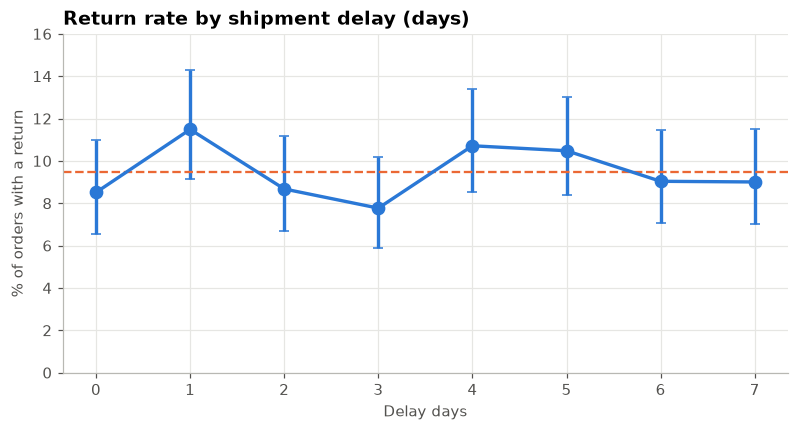

In [29]:
dd = master.groupby('DelayDays').agg(n=('OrderID', 'size'), k=('HasReturn', 'sum')); dd['rate'] = dd.k / dd.n; ci2 = np.array([wilson(k, n) for k, n in zip(dd.k, dd.n)])
fig, ax = plt.subplots(figsize=(8.5, 4)); ax.errorbar(dd.index, dd.rate*100, yerr=[(dd.rate-ci2[:, 0])*100, (ci2[:, 1]-dd.rate)*100], color=BLUE, marker='o', ms=8, lw=2.2, capsize=3)
ax.axhline(master.HasReturn.mean()*100, color=ORANGE, ls='--'); ax.set_ylim(0, 16); ax.set_title('Return rate by shipment delay (days)'); ax.set_xlabel('Delay days'); ax.set_ylabel('% of orders with a return')
rho_dr, p_dr = stats.spearmanr(master.DelayDays, master.HasReturn); R['rho_delay_return'] = float(rho_dr); R['p_delay_return_spearman'] = float(p_dr)
chart('16_delay_vs_returns', 'Delay days vs return rate', f"Return rate does not rise with delay: {pct(dd.rate.iloc[0])} at 0 days vs {pct(dd.rate.iloc[-1])} at 7 days; the correlation is ρ = {rho_dr:.3f} (p = {p_dr:.2f}).",
      'In this data, late delivery does not measurably drive returns, so cutting delays should be justified by service-level and customer-experience goals rather than by an expected fall in returns.')

Chart 17 · Region vs shipment performance
  Interpretation: By destination, Kano has the highest delay rate (65.7%) and Lagos the lowest (61.0%), but the spread is small (χ² p = 0.10); by dispatch city the rates are within one point of each other (p = 0.60).
  Business implication: No region is a significant delay hotspot. Regional delay "league tables" would mislead; the answer to "which region is worst" is "none reliably" — so there is no case for region-specific carrier changes on this evidence.

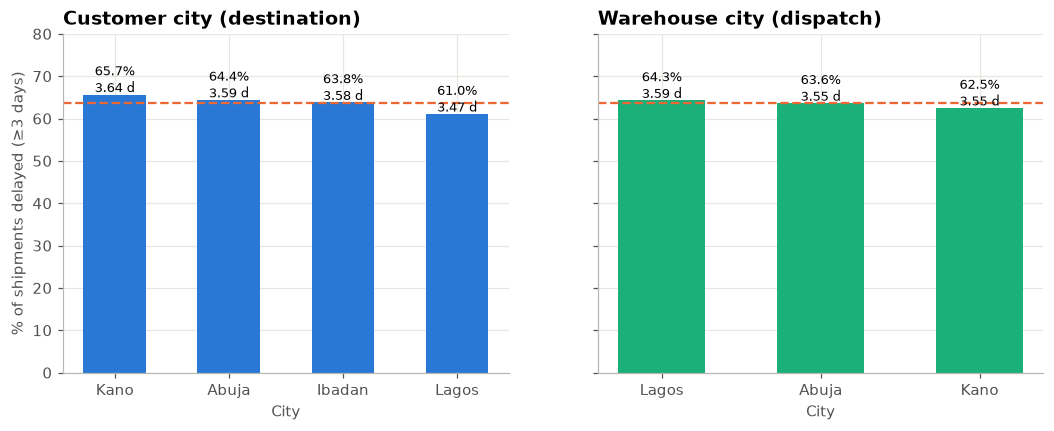

In [30]:
reg = pd.concat({'Customer city (destination)': master.groupby('CustomerCity').agg(n=('OrderID', 'size'), late=('IsDelayed', 'sum'), md=('DelayDays', 'mean')),
                 'Warehouse city (dispatch)': master.groupby('WarehouseCity').agg(n=('OrderID', 'size'), late=('IsDelayed', 'sum'), md=('DelayDays', 'mean'))}); reg['rate'] = reg.late / reg.n
p_cc = stats.chi2_contingency(pd.crosstab(master.CustomerCity, master.IsDelayed))[1]; p_wc = stats.chi2_contingency(pd.crosstab(master.WarehouseCity, master.IsDelayed))[1]
R['p_delay_custcity'] = float(p_cc); R['p_delay_whcity'] = float(p_wc); R['region_delay'] = {f'{a}|{b}': dict(rate=float(r.rate), mean_delay=float(r.md), n=int(r.n)) for (a, b), r in reg.iterrows()}
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4), sharey=True)
for ax, key, colr in zip(axs, reg.index.get_level_values(0).unique(), [BLUE, AQUA]):
    d = reg.loc[key].sort_values('rate', ascending=False); ax.bar(d.index, d.rate*100, color=colr, width=.55)
    for i, (c, r) in enumerate(d.iterrows()): ax.text(i, r.rate*100 + .6, f'{r.rate*100:.1f}%\n{r.md:.2f} d', ha='center', fontsize=8.5)
    ax.axhline(net*100, color=ORANGE, ls='--'); ax.set_title(key); ax.set_xlabel('City'); ax.set_ylim(0, 80)
axs[0].set_ylabel('% of shipments delayed (≥3 days)')
worst_city = reg.loc['Customer city (destination)'].rate.idxmax()
chart('17_region_vs_shipment_performance', 'Region vs shipment performance', f"By destination, {worst_city} has the highest delay rate ({pct(reg.loc['Customer city (destination)'].rate.max())}) and Lagos the lowest ({pct(reg.loc['Customer city (destination)'].rate.min())}), but the spread is small (χ² p = {p_cc:.2f}); by dispatch city the rates are within one point of each other (p = {p_wc:.2f}).",
      'No region is a significant delay hotspot. Regional delay "league tables" would mislead; the answer to "which region is worst" is "none reliably" — so there is no case for region-specific carrier changes on this evidence.')

Chart 18 · Return reason vs delivery outcome
  Interpretation: Only 64% of returns logged as 'Late Delivery' were actually delayed shipments — about the same as 64% of all shipments, and no different from 'Damaged' or 'Wrong Item' returns (χ² p = 0.20).
  Business implication: The 'Late Delivery' reason code is not corroborated by the delivery data: it is either entered inconsistently or the delay field does not reflect what customers experienced. Return reason capture needs an audit and a controlled pick-list.

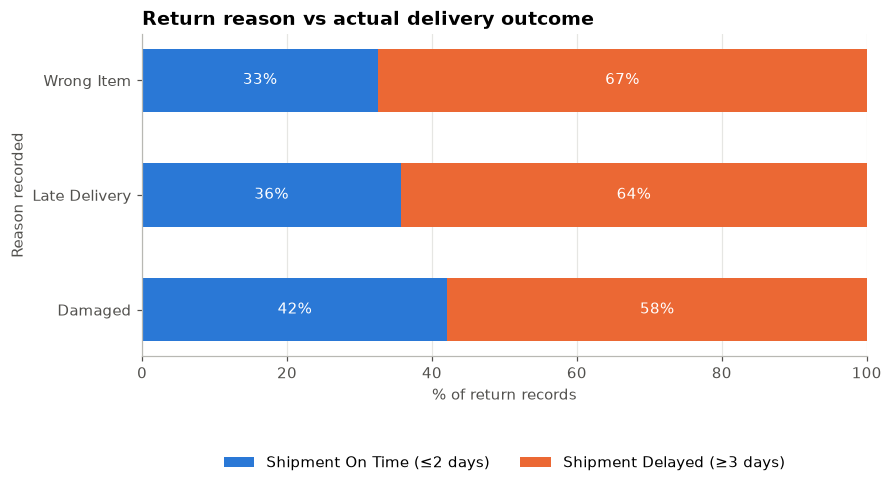

In [31]:
rt2 = cl['Returns'].merge(master[['OrderID', 'IsDelayed', 'DelayDays']], on='OrderID'); ct = pd.crosstab(rt2.Reason, rt2.IsDelayed, normalize='index')*100; p_rr = stats.chi2_contingency(pd.crosstab(rt2.Reason, rt2.IsDelayed))[1]
R['p_reason_delay'] = float(p_rr); R['late_reason_delayed_share'] = float(ct.loc['Late Delivery', 1]/100)
fig, ax = plt.subplots(figsize=(8.5, 3.8)); ax.barh(ct.index, ct[0], color=BLUE, label='Shipment On Time (≤2 days)', height=.55); ax.barh(ct.index, ct[1], left=ct[0], color=ORANGE, label='Shipment Delayed (≥3 days)', height=.55)
for i, (r, row) in enumerate(ct.iterrows()): ax.text(row[0]/2, i, f'{row[0]:.0f}%', ha='center', va='center', color='white', fontsize=9.5); ax.text(row[0]+row[1]/2, i, f'{row[1]:.0f}%', ha='center', va='center', color='white', fontsize=9.5)
ax.set_title('Return reason vs actual delivery outcome'); ax.set_xlabel('% of return records'); ax.set_ylabel('Reason recorded'); ax.legend(loc='lower center', bbox_to_anchor=(.5, -.4), ncol=2); ax.set_xlim(0, 100)
chart('18_reason_vs_delay', 'Return reason vs delivery outcome', f"Only {pct(R['late_reason_delayed_share'],0)} of returns logged as 'Late Delivery' were actually delayed shipments — about the same as {pct(R['delay_rate'],0)} of all shipments, and no different from 'Damaged' or 'Wrong Item' returns (χ² p = {p_rr:.2f}).",
      "The 'Late Delivery' reason code is not corroborated by the delivery data: it is either entered inconsistently or the delay field does not reflect what customers experienced. Return reason capture needs an audit and a controlled pick-list.")

Chart 19 · Monthly revenue trend
  Interpretation: Confirmed revenue averages 1.76M a month, peaking in 2026-08 (2.03M); there is no sustained growth trend across Jan–Aug. Realised (delivered) value is only 33% of gross.
  Business implication: Demand is flat, not growing, and the gap between gross and realised value (≈14.56M) is the real prize. September is partial (to 8 Sep) and must not be read as a decline.

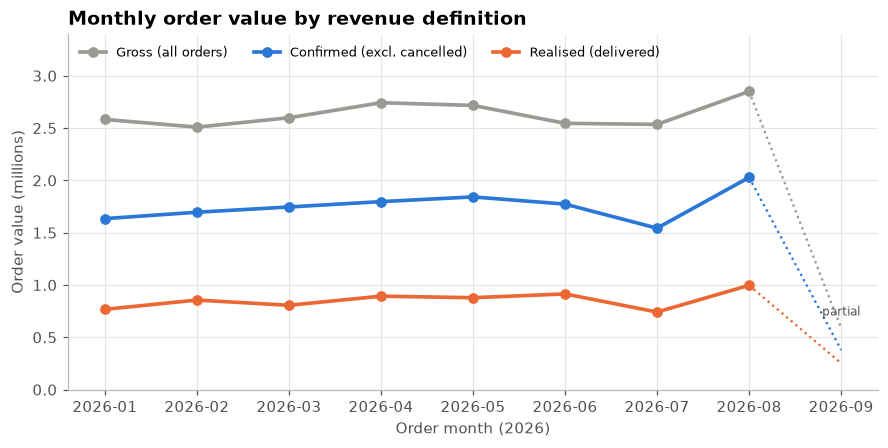

In [32]:
mth = master.groupby('YearMonth').agg(gross=('order_value', 'sum')).join(conf.groupby('YearMonth').order_value.sum().rename('confirmed')).join(master[master.Status == 'Delivered'].groupby('YearMonth').order_value.sum().rename('realised'))
R['monthly_revenue'] = mth.round(0).to_dict('index')
fig, ax = plt.subplots(figsize=(9.5, 4.2)); xi = np.arange(len(mth))
for col, c, lab in [('gross', GREY, 'Gross (all orders)'), ('confirmed', BLUE, 'Confirmed (excl. cancelled)'), ('realised', ORANGE, 'Realised (delivered)')]:
    ax.plot(xi[:-1], mth[col].values[:-1]/1e6, color=c, lw=2.4, marker='o', ms=6, label=lab); ax.plot(xi[-2:], mth[col].values[-2:]/1e6, color=c, lw=1.5, ls=':')
ax.set_xticks(xi); ax.set_xticklabels(mth.index); ax.set_title('Monthly order value by revenue definition'); ax.set_xlabel('Order month (2026)'); ax.set_ylabel('Order value (millions)')
ax.legend(loc='upper left', bbox_to_anchor=(0, 1.0), ncol=3, fontsize=8.5); ax.set_ylim(0, 3.4); ax.text(len(mth)-1, mth.gross.iloc[-1]/1e6 + .12, 'partial', ha='center', fontsize=8, color='#52514e')
pk = mth.confirmed.iloc[:-1].idxmax(); R['peak_revenue_month'] = pk
chart('19_monthly_revenue', 'Monthly revenue trend', f"Confirmed revenue averages {short(mth.confirmed.iloc[:-1].mean())} a month, peaking in {pk} ({short(mth.confirmed.max())}); there is no sustained growth trend across Jan–Aug. Realised (delivered) value is only {pct(R['rev_realised']/R['rev_gross'],0)} of gross.",
      f"Demand is flat, not growing, and the gap between gross and realised value (≈{short(R['rev_gross']-R['rev_realised'])}) is the real prize. September is partial (to 8 Sep) and must not be read as a decline.")

## 3.3 Multivariate analysis — relationships among several variables affecting logistics performance

Chart 20 · Correlation heatmap
  Interpretation: Strong correlations are purely structural (units ↔ order value ↔ lines, delay days ↔ delay flag). Excluding those, the largest relationship between any operational variable pair is |ρ| = 0.02 (order_value vs DelayDays) — effectively zero.
  Business implication: Delivery delay, returns and basket characteristics are statistically unrelated in this dataset. That caps the predictive power any model can extract from these fields and tells SwiftLog that better predictors (carrier, route, dispatch/promise dates, picker, product-level defect flags) must be captured.

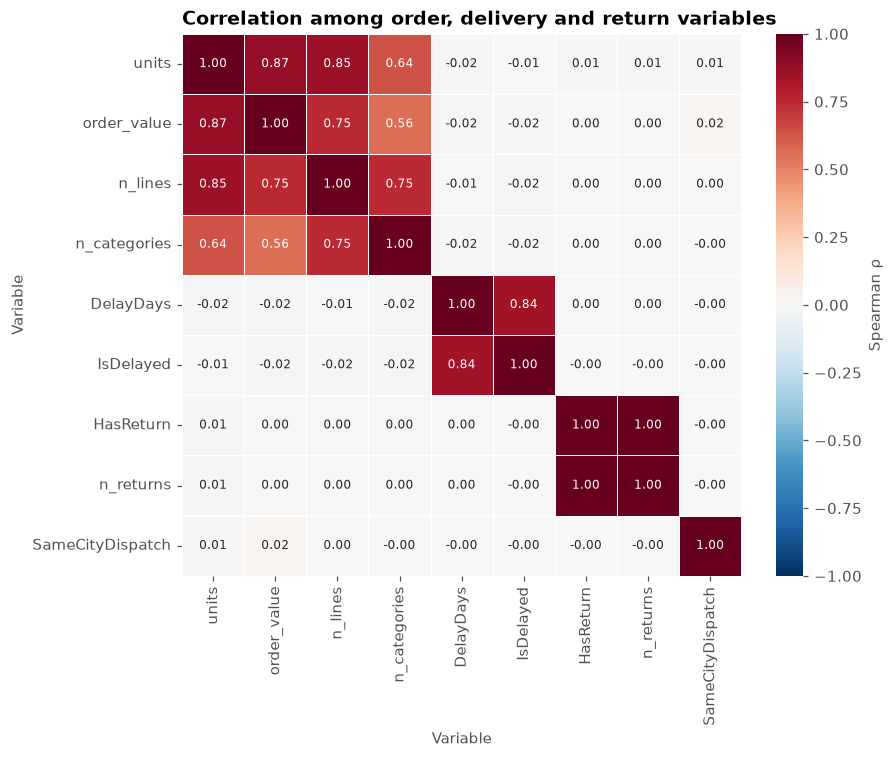

In [33]:
nc = ['units', 'order_value', 'n_lines', 'n_categories', 'DelayDays', 'IsDelayed', 'HasReturn', 'n_returns', 'SameCityDispatch']
cm = master.loc[master.HasItems == 1, nc].corr(method='spearman')
fig, ax = plt.subplots(figsize=(8.2, 6.4)); sns.heatmap(cm, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 8}, linewidths=.5, ax=ax, cbar_kws={'label': 'Spearman ρ'}); ax.grid(False)
ax.set_title('Correlation among order, delivery and return variables'); ax.set_xlabel('Variable'); ax.set_ylabel('Variable')
off = cm.where(~np.eye(len(cm), dtype=bool)).abs(); structural = {('units', 'order_value'), ('order_value', 'units'), ('units', 'n_lines'), ('n_lines', 'units'), ('order_value', 'n_lines'), ('n_lines', 'order_value'), ('DelayDays', 'IsDelayed'), ('IsDelayed', 'DelayDays'), ('HasReturn', 'n_returns'), ('n_returns', 'HasReturn'), ('n_categories', 'n_lines'), ('n_lines', 'n_categories'), ('n_categories', 'units'), ('units', 'n_categories'), ('n_categories', 'order_value'), ('order_value', 'n_categories')}
cross = off.stack(); cross = cross[[i not in structural for i in cross.index]]; mx = cross.max(); mxi = cross.idxmax(); R['max_nonstructural_corr'] = float(mx)
chart('20_correlation_heatmap', 'Correlation heatmap', f"Strong correlations are purely structural (units ↔ order value ↔ lines, delay days ↔ delay flag). Excluding those, the largest relationship between any operational variable pair is |ρ| = {mx:.2f} ({mxi[0]} vs {mxi[1]}) — effectively zero.",
      'Delivery delay, returns and basket characteristics are statistically unrelated in this dataset. That caps the predictive power any model can extract from these fields and tells SwiftLog that better predictors (carrier, route, dispatch/promise dates, picker, product-level defect flags) must be captured.')

Chart 21 · Warehouse × destination delay heatmap
  Interpretation: Across the 60 warehouse–city lanes the delay rate ranges from 49% to 75%, but each lane has only ~84 shipments, so most of the spread is sampling noise (expected ±10 pts).
  Business implication: Lane-level league tables are unreliable at this volume. Before acting on any individual lane, accumulate more shipments or pool lanes (e.g. by region). Monitor with control limits rather than raw ranks.

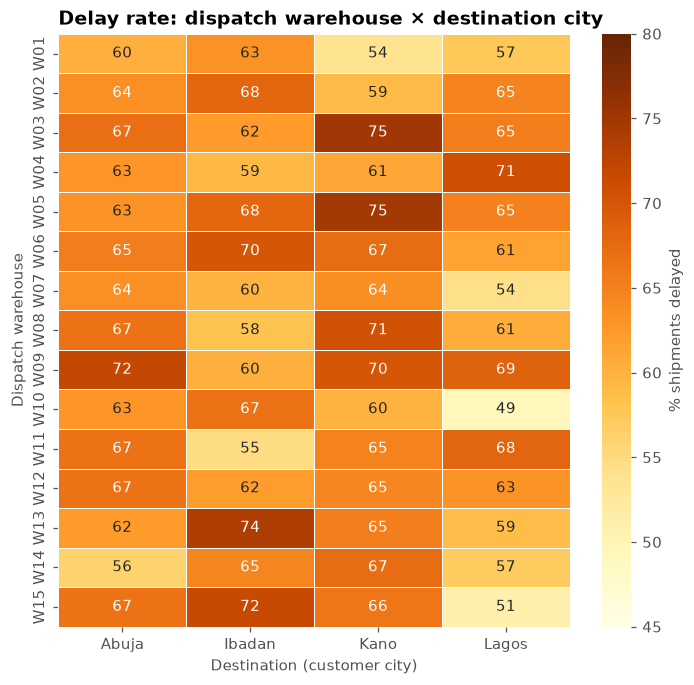

In [34]:
hm = master.pivot_table(index='WarehouseID', columns='CustomerCity', values='IsDelayed', aggfunc='mean')*100; hn = master.pivot_table(index='WarehouseID', columns='CustomerCity', values='IsDelayed', aggfunc='size')
fig, ax = plt.subplots(figsize=(7.5, 7)); sns.heatmap(hm, annot=True, fmt='.0f', cmap='YlOrBr', vmin=45, vmax=80, linewidths=.5, ax=ax, cbar_kws={'label': '% shipments delayed'}); ax.grid(False)
ax.set_title('Delay rate: dispatch warehouse × destination city'); ax.set_xlabel('Destination (customer city)'); ax.set_ylabel('Dispatch warehouse')
R['route_cell_n_median'] = float(hn.stack().median()); R['route_delay_min'] = float(hm.min().min()); R['route_delay_max'] = float(hm.max().max())
chart('21_route_delay_heatmap', 'Warehouse × destination delay heatmap', f"Across the 60 warehouse–city lanes the delay rate ranges from {hm.min().min():.0f}% to {hm.max().max():.0f}%, but each lane has only ~{hn.stack().median():.0f} shipments, so most of the spread is sampling noise (expected ±{1.96*np.sqrt(.64*.36/hn.stack().median())*100:.0f} pts).",
      'Lane-level league tables are unreliable at this volume. Before acting on any individual lane, accumulate more shipments or pool lanes (e.g. by region). Monitor with control limits rather than raw ranks.')

Chart 22 · Workload, delay and stock by warehouse
  Interpretation: Heavier workload per employee is not associated with more delays (ρ = -0.02, p = 0.93, n = 15) and only weakly with low-stock positions (ρ = 0.27, p = 0.32; not significant).
  Business implication: The link between workload and low stock is weak and not statistically significant with only 15 warehouses, so it should be monitored rather than acted on. Workload does not explain delays at all, which again points to network-wide causes.

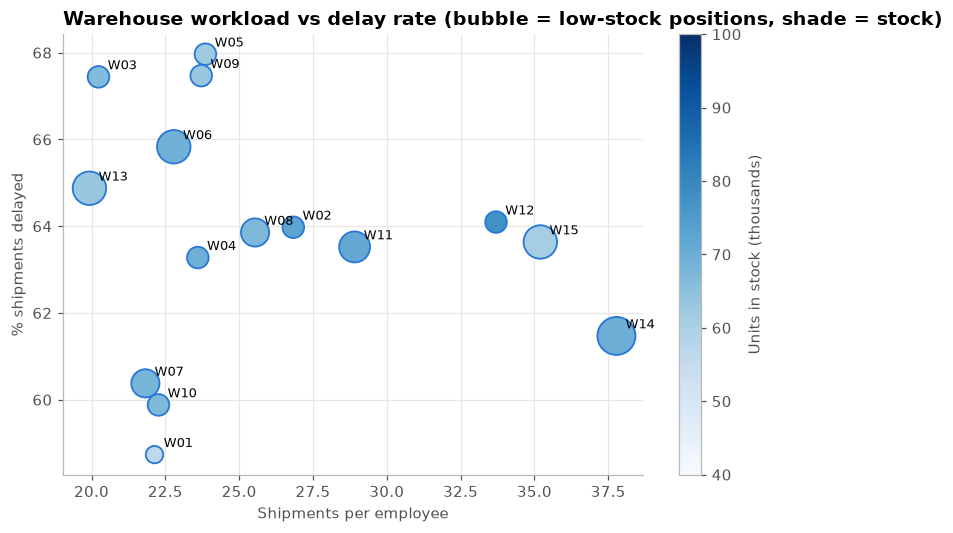

In [35]:
ws = wl.join(wi[['low', 'stock']]).join(dw[['rate']]); ws['low'] = ws.low.astype(int)
rho_ld, p_ld = stats.spearmanr(ws.ship_per_emp, ws.rate); rho_ll, p_ll = stats.spearmanr(ws.ship_per_emp, ws.low); R['rho_load_delay'] = float(rho_ld); R['p_load_delay'] = float(p_ld); R['rho_load_low'] = float(rho_ll); R['p_load_low'] = float(p_ll)
fig, ax = plt.subplots(figsize=(8.5, 5.2)); sc = ax.scatter(ws.ship_per_emp, ws.rate*100, s=60 + ws.low*70, c=ws.stock/1000, cmap='Blues', edgecolor=BLUE, lw=1.2, vmin=40, vmax=100)
for w, r in ws.iterrows(): ax.annotate(w, (r.ship_per_emp, r.rate*100), xytext=(6, 5), textcoords='offset points', fontsize=8.5)
ax.set_title('Warehouse workload vs delay rate (bubble = low-stock positions, shade = stock)'); ax.set_xlabel('Shipments per employee'); ax.set_ylabel('% shipments delayed'); plt.colorbar(sc, label='Units in stock (thousands)')
chart('22_workload_delay_stock_bubble', 'Workload, delay and stock by warehouse', f"Heavier workload per employee is not associated with more delays (ρ = {rho_ld:.2f}, p = {p_ld:.2f}, n = 15) and only weakly with low-stock positions (ρ = {rho_ll:.2f}, p = {p_ll:.2f}; not significant).",
      'The link between workload and low stock is weak and not statistically significant with only 15 warehouses, so it should be monitored rather than acted on. Workload does not explain delays at all, which again points to network-wide causes.')

Chart 23 · Order status vs delay and returns
  Interpretation: Cancelled and Pending orders show the same delay (64% / 64%) and return rates (9.2% / 9.6%) as Delivered orders: 1,626 shipments and 161 returns are recorded against Cancelled orders.
  Business implication: A cancelled order cannot be shipped late or returned. Either status is not being updated (systems out of sync) or shipment/return records are mis-keyed. Until fixed, every delivery KPI is contaminated — reconciling order status with shipment and return events is a prerequisite for trustworthy analytics and ML.

Total charts produced so far: 23 (brief requires at least 15).

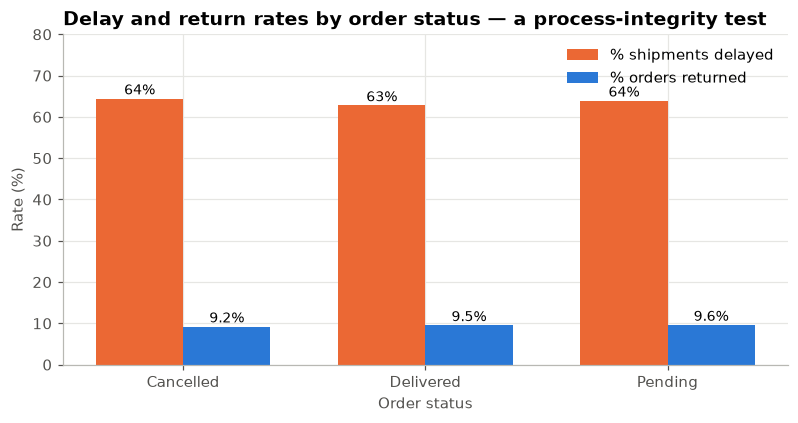

In [36]:
sc_ = master.groupby('Status').agg(n=('OrderID', 'size'), delay=('IsDelayed', 'mean'), ret=('HasReturn', 'mean'), value=('order_value', 'sum'))
R['status_table'] = sc_.round(4).to_dict('index'); R['returns_on_nondelivered'] = int(R['dq']['Returns recorded against non-Delivered orders']); R['ship_on_cancelled'] = int(R['dq']['Shipments recorded for CANCELLED orders'])
fig, ax = plt.subplots(figsize=(8.5, 3.9)); xx = np.arange(3); w_ = .36; ax.bar(xx - w_/2, sc_.delay*100, w_, color=ORANGE, label='% shipments delayed'); ax.bar(xx + w_/2, sc_.ret*100, w_, color=BLUE, label='% orders returned')
for i, (s, r) in enumerate(sc_.iterrows()): ax.text(i - w_/2, r.delay*100 + 1, f'{r.delay*100:.0f}%', ha='center', fontsize=9); ax.text(i + w_/2, r.ret*100 + 1, f'{r.ret*100:.1f}%', ha='center', fontsize=9)
ax.set_xticks(xx); ax.set_xticklabels(sc_.index); ax.set_title('Delay and return rates by order status — a process-integrity test'); ax.set_xlabel('Order status'); ax.set_ylabel('Rate (%)'); ax.legend(); ax.set_ylim(0, 80)
chart('23_status_integrity', 'Order status vs delay and returns', f"Cancelled and Pending orders show the same delay ({pct(sc_.delay['Cancelled'],0)} / {pct(sc_.delay['Pending'],0)}) and return rates ({pct(sc_.ret['Cancelled'])} / {pct(sc_.ret['Pending'])}) as Delivered orders: {R['ship_on_cancelled']:,} shipments and {int(cl['Returns'].merge(master[['OrderID','Status']], on='OrderID').query('Status==\"Cancelled\"').shape[0])} returns are recorded against Cancelled orders.",
      'A cancelled order cannot be shipped late or returned. Either status is not being updated (systems out of sync) or shipment/return records are mis-keyed. Until fixed, every delivery KPI is contaminated — reconciling order status with shipment and return events is a prerequisite for trustworthy analytics and ML.')
print(f'\nTotal charts produced so far: {len(CH)} (brief requires at least 15).')

---
# PART 4 — Statistical Analysis
Tests use α = 0.05 and are reported with an **effect size**. Because we run several tests, a Bonferroni-adjusted threshold (α/k) is also shown: a result only counts as robust if it survives it.

In [37]:
num = master.loc[master.HasItems == 1, ['units', 'order_value', 'n_lines', 'DelayDays']]
ds = num.describe().T; ds['skew'] = num.skew(); ds['kurtosis'] = num.kurt(); ds['cv'] = ds['std'] / ds['mean']
R['desc_stats'] = ds.round(3).to_dict('index')
ds.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,cv
units,"4,764.000",17.310,10.380,1.000,10.000,16.000,23.000,71.000,0.870,0.800,0.600
order_value,"4,764.000","4,548.290","3,148.910",11.780,"2,168.370","3,949.470","6,280.250","19,290.340",0.990,0.980,0.690
n_lines,"4,764.000",3.130,1.620,1.000,2.000,3.000,4.000,11.000,0.770,0.430,0.520
DelayDays,"4,764.000",3.570,2.300,0.000,2.000,4.000,6.000,7.000,-0.050,-1.240,0.640


In [38]:
nt = pd.DataFrame({v: dict(shapiro_p=stats.shapiro(num[v].sample(min(len(num), 4000), random_state=1))[1], skew=stats.skew(num[v])) for v in num}).T
print('Normality (Shapiro–Wilk on up to 4,000 rows): p < 0.05 means NOT normal. Right-skewed order value and units favour non-parametric tests (Mann–Whitney, Kruskal–Wallis, Spearman).')
nt.round(4)

Normality (Shapiro–Wilk on up to 4,000 rows): p < 0.05 means NOT normal. Right-skewed order value and units favour non-parametric tests (Mann–Whitney, Kruskal–Wallis, Spearman).

,shapiro_p,skew
units,0.000,0.872
order_value,0.000,0.993
n_lines,0.000,0.765
DelayDays,0.000,-0.052


In [39]:
def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct, correction=False)[0]; n = ct.values.sum(); return float(np.sqrt(chi2 / (n * (min(ct.shape) - 1))))
tests = []
def add(name, h0, test, stat, p, eff_name, eff):
    tests.append(dict(test=name, H0=h0, method=test, statistic=round(float(stat), 3), p_value=float(p), effect_size=f'{eff_name} = {eff:.3f}'))
ct = pd.crosstab(master.WarehouseID, master.IsDelayed); c = stats.chi2_contingency(ct); add('T1 Delay vs warehouse', 'Delay rate is equal across the 15 warehouses', 'Chi-square independence', c[0], c[1], "Cramér's V", cramers_v(ct))
ct = pd.crosstab(master.CustomerCity, master.IsDelayed); c = stats.chi2_contingency(ct); add('T2 Delay vs destination city', 'Delay rate is equal across the 4 cities', 'Chi-square independence', c[0], c[1], "Cramér's V", cramers_v(ct))
ct = pd.crosstab(master.IsDelayed, master.HasReturn); c = stats.chi2_contingency(ct); add('T3 Returns vs delay', 'Return rate is the same for delayed and on-time orders', 'Chi-square independence', c[0], c[1], "Cramér's V", cramers_v(ct))
a, b = master.loc[(master.IsDelayed == 1) & (master.HasItems == 1), 'order_value'], master.loc[(master.IsDelayed == 0) & (master.HasItems == 1), 'order_value']
u = stats.mannwhitneyu(a, b); add('T4 Order value: delayed vs on-time', 'Order value distributions are equal', 'Mann–Whitney U', u[0], u[1], 'rank-biserial r', 1 - 2*u[0]/(len(a)*len(b)))
g = [d.order_value.values for _, d in master[master.HasItems == 1].groupby('DominantCategory')]; k = stats.kruskal(*g); n_ = sum(map(len, g)); add('T5 Order value by dominant category', 'Order value is equal across categories', 'Kruskal–Wallis', k[0], k[1], 'epsilon²', k[0] / (n_ - 1))
g = [d.order_value.values for _, d in master[master.HasItems == 1].groupby('Status')]; k = stats.kruskal(*g); add('T6 Order value by status', 'Order value is equal across statuses', 'Kruskal–Wallis', k[0], k[1], 'epsilon²', k[0] / (n_ - 1))
ct = pd.crosstab(master.SameCityDispatch, master.IsDelayed); c = stats.chi2_contingency(ct); add('T7 Delay: same-city vs cross-city dispatch', 'Delay rate is equal whether or not warehouse and customer are in the same city', 'Chi-square independence', c[0], c[1], "Cramér's V", cramers_v(ct))
ct = pd.crosstab(master.CustomerCity, master.Status); c = stats.chi2_contingency(ct); add('T8 Cancellation vs destination city', 'Order status mix is equal across cities', 'Chi-square independence', c[0], c[1], "Cramér's V", cramers_v(ct))
r_, p_ = stats.spearmanr(master.units[master.HasItems == 1], master.DelayDays[master.HasItems == 1]); add('T9 Basket size vs delay days', 'No monotonic relationship', 'Spearman correlation', r_, p_, 'rho', r_)
ct = pd.crosstab(master.WarehouseID, master.HasReturn); c = stats.chi2_contingency(ct); add('T10 Returns vs warehouse', 'Return rate is equal across warehouses', 'Chi-square independence', c[0], c[1], "Cramér's V", cramers_v(ct))
T = pd.DataFrame(tests); alpha_b = 0.05 / len(T)
T['significant_0.05'] = np.where(T.p_value < .05, 'Yes', 'No'); T['survives_Bonferroni'] = np.where(T.p_value < alpha_b, 'Yes', 'No'); T['p_value'] = T.p_value.round(4)
R['tests'] = T.to_dict('records'); R['bonferroni_alpha'] = alpha_b; R['n_sig_raw'] = int((T.p_value < .05).sum()); R['n_sig_bonf'] = int((T.p_value < alpha_b).sum())
print(f'{len(T)} tests run. Significant at 0.05: {R["n_sig_raw"]}; surviving Bonferroni (α = {alpha_b:.4f}): {R["n_sig_bonf"]}.')
T[['test', 'method', 'statistic', 'p_value', 'effect_size', 'significant_0.05', 'survives_Bonferroni']]

10 tests run. Significant at 0.05: 0; surviving Bonferroni (α = 0.0050): 0.

,test,method,statistic,p_value,effect_size,significant_0.05,survives_Bonferroni
0,T1 Delay vs warehouse,Chi-square independence,15.764,0.328,Cramér's V = 0.056,No,No
1,T2 Delay vs destination city,Chi-square independence,6.267,0.099,Cramér's V = 0.035,No,No
2,T3 Returns vs delay,Chi-square independence,0.008,0.928,Cramér's V = 0.002,No,No
3,T4 Order value: delayed vs on-time,Mann–Whitney U,"2,563,467.500",0.160,rank-biserial r = 0.024,No,No
4,T5 Order value by dominant category,Kruskal–Wallis,4.609,0.100,epsilon² = 0.001,No,No
5,T6 Order value by status,Kruskal–Wallis,4.082,0.130,epsilon² = 0.001,No,No
6,T7 Delay: same-city vs cross-city dispatch,Chi-square independence,0.007,0.936,Cramér's V = 0.002,No,No
7,T8 Cancellation vs destination city,Chi-square independence,1.450,0.963,Cramér's V = 0.012,No,No
8,T9 Basket size vs delay days,Spearman correlation,-0.017,0.229,rho = -0.017,No,No
9,T10 Returns vs warehouse,Chi-square independence,15.585,0.339,Cramér's V = 0.056,No,No


In [40]:
for _, t in T.iterrows():
    verdict = ('Statistically significant' + (' and survives the Bonferroni correction.' if t.survives_Bonferroni == 'Yes' else ' at 0.05 but NOT after Bonferroni correction — treat as a possible false positive.')) if t['significant_0.05'] == 'Yes' else 'No significant difference — we fail to reject H0; the observed gap is consistent with chance.'
    print(f"{t.test}\n  H0: {t.H0}\n  Result: {t.method}, p = {t.p_value:.4f}, {t.effect_size}. {verdict}\n")
print('Business reading: delivery delay, returns, order value and warehouse/region show no reliable relationship in this extract. The operational story is therefore a network-wide delay level (63.7%), not a "problem warehouse" or "problem region".')

T1 Delay vs warehouse
  H0: Delay rate is equal across the 15 warehouses
  Result: Chi-square independence, p = 0.3280, Cramér's V = 0.056. No significant difference — we fail to reject H0; the observed gap is consistent with chance.

T2 Delay vs destination city
  H0: Delay rate is equal across the 4 cities
  Result: Chi-square independence, p = 0.0993, Cramér's V = 0.035. No significant difference — we fail to reject H0; the observed gap is consistent with chance.

T3 Returns vs delay
  H0: Return rate is the same for delayed and on-time orders
  Result: Chi-square independence, p = 0.9283, Cramér's V = 0.002. No significant difference — we fail to reject H0; the observed gap is consistent with chance.

T4 Order value: delayed vs on-time
  H0: Order value distributions are equal
  Result: Mann–Whitney U, p = 0.1600, rank-biserial r = 0.024. No significant difference — we fail to reject H0; the observed gap is consistent with chance.

T5 Order value by dominant category
  H0: Order va

In [41]:
lo, hi = wilson(int(master.IsDelayed.sum()), len(master)); lo2, hi2 = wilson(int(master.HasReturn.sum()), len(master))
ci_tab = pd.DataFrame({'metric': ['Delayed shipments (≥3 days)', 'Orders with a return'], 'estimate': [master.IsDelayed.mean(), master.HasReturn.mean()], 'ci_low': [lo, lo2], 'ci_high': [hi, hi2]})
R['delay_ci'] = [float(lo), float(hi)]; R['return_ci'] = [float(lo2), float(hi2)]
ci_tab.round(4)

,metric,estimate,ci_low,ci_high
0,Delayed shipments (≥3 days),0.637,0.624,0.650
1,Orders with a return,0.095,0.087,0.103


---
# PART 5 — Feature Engineering
**Grain:** one row per order (5,000). **Targets:** `IsDelayed` (delay ≥ 3 days), `DelayDays`, `HasReturn`.
**Leakage rule:** any feature about the customer or warehouse uses only information available *before* the order (expanding, shifted history). Post-outcome fields (`DelayDays`, `n_returns`, `ReturnReasons`, `Status` for a not-yet-final order) are never used as predictors.
Every feature is documented with: why it was created, its business value and its ML value (see the feature dictionary below).

In [42]:
fe = master.sort_values(['OrderDate', 'OrderID']).reset_index(drop=True).copy()
fe['OrderDate'] = pd.to_datetime(fe.OrderDate)
FD = []  # feature dictionary
def feat(name, why, biz, ml, group): FD.append(dict(feature=name, group=group, why_created=why, business_value=biz, ml_value=ml))

# --- Time features
fe['IsWeekend'] = (fe.OrderDate.dt.dayofweek >= 5).astype(int); fe['DayOfMonth'] = fe.OrderDate.dt.day; fe['IsMonthEnd'] = (fe.OrderDate.dt.day >= 25).astype(int)
fe['DaysSinceStart'] = (fe.OrderDate - fe.OrderDate.min()).dt.days
feat('IsWeekend', 'Weekend dispatch often has thinner staffing', 'Tests whether weekend orders need different cut-offs', 'Binary calendar signal; captures weekly seasonality', 'Time')
feat('IsMonthEnd', 'Month-end (day ≥ 25) volume peaks are common in logistics', 'Flags peak-load days for roster planning', 'Captures intra-month cycles', 'Time')
feat('DaysSinceStart', 'Continuous time index', 'Lets trend be tracked', 'Allows a model to learn drift; also used for the time-ordered train/test split', 'Time')

# --- Order / basket features
fe['value_per_unit'] = fe.order_value / fe.units.replace(0, np.nan); fe['log_order_value'] = np.log1p(fe.order_value)
fe['units_per_line'] = fe.units / fe.n_lines.replace(0, np.nan); fe['is_multi_category'] = (fe.n_categories > 1).astype(int)
q75 = fe.order_value.quantile(.75); fe['is_high_value'] = (fe.order_value >= q75).astype(int); fe['is_bulk'] = (fe.units >= fe.units.quantile(.75)).astype(int)
feat('value_per_unit', 'Average price of what is in the basket', 'Separates premium from commodity baskets', 'Scale-free value signal, less correlated with size than order_value', 'Basket')
feat('log_order_value', 'Order value is right-skewed (skew ≈ 1)', 'None directly (modelling aid)', 'Reduces skew for linear/distance-based models', 'Basket')
feat('units_per_line', 'Handling effort per product line', 'Proxy for pick complexity', 'Captures bulk vs spread baskets', 'Basket')
feat('is_multi_category', 'Multi-category orders may need multiple picks', 'Flags complex fulfilment', 'Binary complexity indicator', 'Basket')
feat('is_high_value / is_bulk', 'Top-quartile value / size', 'Identifies orders worth prioritising or protecting', 'Non-linear threshold features for tree and linear models', 'Basket')

# --- Customer history (strictly prior orders)
fe['cust_prior_orders'] = fe.groupby('CustomerID').cumcount()
fe['cust_prior_value'] = fe.groupby('CustomerID').order_value.cumsum() - fe.order_value
fe['cust_avg_prior_value'] = (fe.cust_prior_value / fe.cust_prior_orders.replace(0, np.nan))
fe['days_since_prev_order'] = fe.groupby('CustomerID').OrderDate.diff().dt.days
fe['is_repeat_customer'] = (fe.cust_prior_orders > 0).astype(int)
fe['value_vs_cust_avg'] = (fe.order_value / fe.cust_avg_prior_value.replace(0, np.nan))
feat('cust_prior_orders', 'Order count before this order', 'Loyalty/frequency, the F in RFM', 'Captures customer behaviour without leaking the current outcome', 'Customer')
feat('cust_prior_value', 'Cumulative spend before this order', 'Customer lifetime value to date (the M in RFM)', 'Monetary history signal', 'Customer')
feat('cust_avg_prior_value', 'Average prior basket', 'Typical spend level', 'Baseline for detecting unusual baskets', 'Customer')
feat('days_since_prev_order', 'Recency gap between orders', 'Early-warning for churn (long gaps)', 'Recency signal (the R in RFM)', 'Customer')
feat('is_repeat_customer', 'First order vs returning', 'Onboarding vs retention experience', 'Simple, stable binary', 'Customer')
feat('value_vs_cust_avg', 'This basket relative to customer norm', 'Spots unusually large/small orders', 'Normalised value; reduces between-customer variance', 'Customer')

# --- Warehouse features (static capacity proxies + prior performance)
whs = pd.DataFrame({'wh_staff': emp, 'wh_total_stock': wi.stock, 'wh_low_stock_share': wi.low / wi.positions, 'wh_shipments_total': wl.shipments}); whs['wh_workload_per_emp'] = whs.wh_shipments_total / whs.wh_staff
fe = fe.merge(whs[['wh_staff', 'wh_total_stock', 'wh_low_stock_share', 'wh_workload_per_emp']], left_on='WarehouseID', right_index=True, how='left')
fe['wh_prior_delay_rate'] = fe.groupby('WarehouseID').IsDelayed.transform(lambda s: s.shift().rolling(50, min_periods=10).mean())
fe['wh_prior_avg_delay'] = fe.groupby('WarehouseID').DelayDays.transform(lambda s: s.shift().rolling(50, min_periods=10).mean())
_tmp = []
for w, g in fe.groupby('WarehouseID'):
    s = g.set_index('OrderDate').OrderID.rolling('7D').count() - 1; _tmp.append(pd.Series(s.values, index=g.index))
fe['wh_orders_last7d'] = pd.concat(_tmp).sort_index()
fe['wh_load_index'] = fe.wh_orders_last7d / fe.wh_staff
feat('wh_staff', 'Headcount at dispatch site', 'Capacity proxy (true capacity not in data)', 'Static site attribute', 'Warehouse')
feat('wh_total_stock / wh_low_stock_share', 'Site stock level and share of positions below 20 units', 'Replenishment risk indicator', 'Stock-pressure signal at the site', 'Warehouse')
feat('wh_workload_per_emp', 'Season-long shipments ÷ staff', 'Staffing imbalance', 'Site load level', 'Warehouse')
feat('wh_prior_delay_rate / wh_prior_avg_delay', 'Rolling delay over the previous 50 shipments of the same warehouse', 'Live reliability monitor', 'Time-safe warehouse performance feature (no look-ahead)', 'Warehouse')
feat('wh_orders_last7d / wh_load_index', 'Orders handled by the site in the previous 7 days, per employee', 'Short-term congestion', 'Dynamic load feature', 'Warehouse')

# --- Route / geography
fe['route'] = fe.WarehouseCity + '→' + fe.CustomerCity
feat('SameCityDispatch', 'Warehouse and customer in the same city', 'Local vs long-haul fulfilment', 'Distance proxy (no coordinates in data)', 'Route')
feat('route', 'Origin city → destination city', 'Lane-level reporting', 'Categorical lane feature (12 combos)', 'Route')

# --- Encodings
cat_cols = ['CustomerCity', 'WarehouseCity', 'DominantCategory']
oh = pd.get_dummies(fe[cat_cols], prefix=['cust_city', 'wh_city', 'cat'], dtype=int); fe = pd.concat([fe, oh], axis=1)
fe['Status_code'] = fe.Status.map({'Cancelled': 0, 'Pending': 1, 'Delivered': 2}); fe['DayOfWeek_num'] = fe.OrderDate.dt.dayofweek; fe['Month_sin'] = np.sin(2*np.pi*fe.Month/12); fe['Month_cos'] = np.cos(2*np.pi*fe.Month/12)
feat('one-hot: cust_city_*, wh_city_*, cat_*', 'Nominal variables cannot be used raw by most models', 'None directly', 'One-hot encoding avoids false ordering (few levels, so no high-cardinality issue)', 'Encoding')
feat('Month_sin / Month_cos', 'Cyclical encoding of month', 'None directly', 'Lets models see December and January as neighbours', 'Encoding')
feat('Status_code', 'Ordinal status (Cancelled < Pending < Delivered)', 'Funnel stage', 'Ordinal encoding; NOT used as a delay predictor because status can be set after the outcome', 'Encoding')

# --- Return-risk flags (targets & diagnostics)
fe['target_is_delayed'] = fe.IsDelayed; fe['target_delay_days'] = fe.DelayDays; fe['target_has_return'] = fe.HasReturn
fe = fe.replace([np.inf, -np.inf], np.nan)
FD_df = pd.DataFrame(FD); R['n_features_documented'] = len(FD_df)
print(f'Feature-engineered table: {fe.shape[0]:,} rows × {fe.shape[1]} columns. {len(FD_df)} feature groups documented.')
FD_df

Feature-engineered table: 5,000 rows × 75 columns. 24 feature groups documented.

,feature,group,why_created,business_value,ml_value
0,IsWeekend,Time,Weekend dispatch often has thinner staffing,Tests whether weekend orders need different cut-offs,Binary calendar signal; captures weekly seasonality
1,IsMonthEnd,Time,Month-end (day ≥ 25) volume peaks are common in logistics,Flags peak-load days for roster planning,Captures intra-month cycles
2,DaysSinceStart,Time,Continuous time index,Lets trend be tracked,Allows a model to learn drift; also used for the time-ordered train/test split
3,value_per_unit,Basket,Average price of what is in the basket,Separates premium from commodity baskets,"Scale-free value signal, less correlated with size than order_value"
4,log_order_value,Basket,Order value is right-skewed (skew ≈ 1),None directly (modelling aid),Reduces skew for linear/distance-based models
5,units_per_line,Basket,Handling effort per product line,Proxy for pick complexity,Captures bulk vs spread baskets
6,is_multi_category,Basket,Multi-category orders may need multiple picks,Flags complex fulfilment,Binary complexity indicator
7,is_high_value / is_bulk,Basket,Top-quartile value / size,Identifies orders worth prioritising or protecting,Non-linear threshold features for tree and linear models
8,cust_prior_orders,Customer,Order count before this order,"Loyalty/frequency, the F in RFM",Captures customer behaviour without leaking the current outcome
9,cust_prior_value,Customer,Cumulative spend before this order,Customer lifetime value to date (the M in RFM),Monetary history signal


In [43]:
# Missing values are structural (first orders have no history) - impute with explicit flags rather than silently filling
hist_cols = ['cust_avg_prior_value', 'days_since_prev_order', 'value_vs_cust_avg', 'wh_prior_delay_rate', 'wh_prior_avg_delay', 'value_per_unit', 'units_per_line']
miss = fe[hist_cols].isna().sum().to_frame('missing'); miss['why'] = ['first order of customer', 'first order of customer', 'first order of customer', 'warehouse warm-up (<10 shipments)', 'warehouse warm-up (<10 shipments)', 'order has no line items', 'order has no line items']
R['fe_missing'] = miss.missing.to_dict()
miss

,missing,why
cust_avg_prior_value,991,first order of customer
days_since_prev_order,991,first order of customer
value_vs_cust_avg,1037,first order of customer
wh_prior_delay_rate,150,warehouse warm-up (<10 shipments)
wh_prior_avg_delay,150,warehouse warm-up (<10 shipments)
value_per_unit,236,order has no line items
units_per_line,236,order has no line items


In [44]:
# Final modelling table: impute (median) + keep raw columns for transparency; save
model_df = fe.copy()
for c in hist_cols: model_df[c + '_missing'] = model_df[c].isna().astype(int); model_df[c] = model_df[c].fillna(model_df[c].median())
model_df.to_csv(f'{BASE}/Data/Feature_Engineered_Dataset.csv', index=False)
R['fe_shape'] = list(model_df.shape)
print(f'Saved Data/Feature_Engineered_Dataset.csv {model_df.shape}')

Saved Data/Feature_Engineered_Dataset.csv (5000, 82)

In [45]:
# Feature screening against targets (non-parametric): which engineered features carry ANY signal?
cand = ['units', 'order_value', 'n_lines', 'n_categories', 'value_per_unit', 'units_per_line', 'cust_prior_orders', 'cust_prior_value', 'days_since_prev_order', 'value_vs_cust_avg', 'wh_staff', 'wh_total_stock', 'wh_low_stock_share', 'wh_workload_per_emp', 'wh_prior_delay_rate', 'wh_orders_last7d', 'wh_load_index', 'SameCityDispatch', 'IsWeekend', 'IsMonthEnd', 'DaysSinceStart', 'is_repeat_customer', 'is_high_value', 'is_multi_category']
sc = pd.DataFrame({c: dict(rho_delay=stats.spearmanr(model_df[c], model_df.DelayDays)[0], p_delay=stats.spearmanr(model_df[c], model_df.DelayDays)[1], rho_return=stats.spearmanr(model_df[c], model_df.HasReturn)[0], p_return=stats.spearmanr(model_df[c], model_df.HasReturn)[1]) for c in cand}).T
sc['abs_max'] = sc[['rho_delay', 'rho_return']].abs().max(axis=1); sc = sc.sort_values('abs_max', ascending=False)
R['feature_screen_max'] = float(sc.abs_max.max()); R['feature_screen_top'] = sc.head(5).round(4).to_dict('index')
n_sig = int(((sc.p_delay < .05) | (sc.p_return < .05)).sum()); R['feature_screen_nsig'] = n_sig; print(f'{n_sig} of {len(sc)} features reach p<0.05 against a target (about {len(sc)*2*.05:.0f} expected by chance alone); strongest |rho| = {sc.abs_max.max():.3f}.')
sc.round(4).head(10)

2 of 24 features reach p<0.05 against a target (about 2 expected by chance alone); strongest |rho| = 0.034.

,rho_delay,p_delay,rho_return,p_return,abs_max
is_high_value,-0.034,0.017,-0.013,0.357,0.034
wh_prior_delay_rate,-0.030,0.035,-0.006,0.644,0.030
order_value,-0.023,0.102,0.002,0.869,0.023
value_vs_cust_avg,-0.020,0.155,-0.002,0.915,0.020
units,-0.018,0.193,0.008,0.576,0.018
n_categories,-0.018,0.200,0.001,0.928,0.018
units_per_line,-0.018,0.212,0.016,0.256,0.018
IsMonthEnd,0.008,0.593,-0.018,0.216,0.018
wh_staff,-0.001,0.938,0.018,0.217,0.018
DaysSinceStart,0.014,0.338,-0.016,0.256,0.016


In [46]:
# Baseline predictive test (time-ordered split: first 70% train, last 30% test) – what can ML achieve today?
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
X_cols = [c for c in cand] + [c for c in model_df.columns if c.startswith(('cust_city_', 'wh_city_', 'cat_'))] + ['Month_sin', 'Month_cos', 'DayOfWeek_num']
cut = int(len(model_df) * .7); tr, te = model_df.iloc[:cut], model_df.iloc[cut:]
res = []
for tgt in ['IsDelayed', 'HasReturn']:
    base = max(te[tgt].mean(), 1 - te[tgt].mean())
    for name, m in [('Logistic regression', make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))), ('Random forest', RandomForestClassifier(300, min_samples_leaf=20, random_state=7, n_jobs=-1)), ('Gradient boosting', GradientBoostingClassifier(random_state=7, max_depth=2))]:
        m.fit(tr[X_cols], tr[tgt]); pr = m.predict_proba(te[X_cols])[:, 1]; res.append(dict(target=tgt, model=name, test_AUC=roc_auc_score(te[tgt], pr), accuracy=float(((pr > .5) == te[tgt]).mean()), majority_baseline=base))
ML = pd.DataFrame(res); R['ml_baseline'] = ML.round(4).to_dict('records'); R['best_auc_delay'] = float(ML[ML.target == 'IsDelayed'].test_AUC.max()); R['best_auc_return'] = float(ML[ML.target == 'HasReturn'].test_AUC.max())
print('AUC 0.50 = coin flip. Anything under ~0.60 means the features carry essentially no usable signal for that target.')
ML.round(3)

AUC 0.50 = coin flip. Anything under ~0.60 means the features carry essentially no usable signal for that target.

,target,model,test_AUC,accuracy,majority_baseline
0,IsDelayed,Logistic regression,0.495,0.469,0.651
1,IsDelayed,Random forest,0.516,0.649,0.651
2,IsDelayed,Gradient boosting,0.521,0.501,0.651
3,HasReturn,Logistic regression,0.451,0.915,0.915
4,HasReturn,Random forest,0.500,0.915,0.915
5,HasReturn,Gradient boosting,0.515,0.912,0.915


Chart 24 · Feature importance (delay model)
  Interpretation: Importance is spread thinly across features, led by value_per_unit and order_value; with a test AUC of only 0.52 the ranking mostly reflects noise rather than real drivers.
  Business implication: Today's extract cannot predict delays. Useful ML needs new inputs: carrier, route distance, promised vs actual dates, picker/shift, weather and stock availability at pick time.

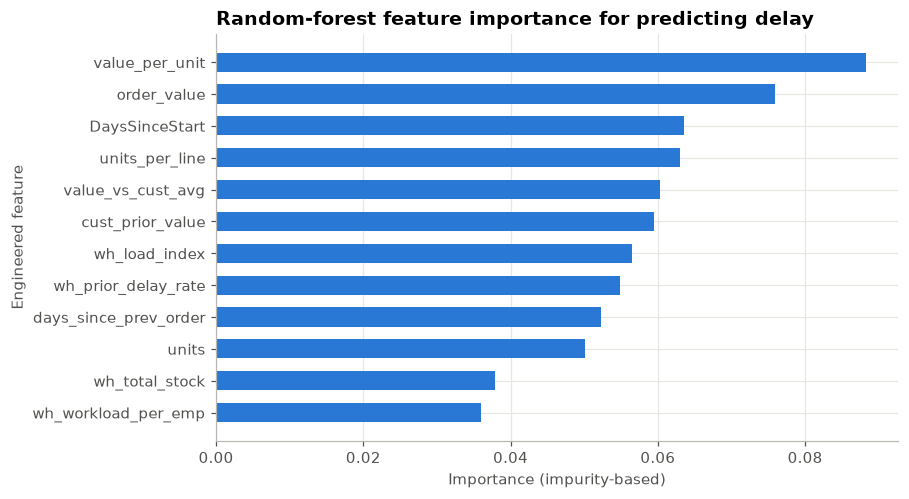

In [47]:
rf = RandomForestClassifier(300, min_samples_leaf=20, random_state=7, n_jobs=-1).fit(tr[X_cols], tr.IsDelayed)
imp = pd.Series(rf.feature_importances_, X_cols).sort_values(ascending=False).head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.8)); ax.barh(imp.index, imp.values, color=BLUE, height=.6); ax.set_title('Random-forest feature importance for predicting delay'); ax.set_xlabel('Importance (impurity-based)'); ax.set_ylabel('Engineered feature')
chart('24_feature_importance', 'Feature importance (delay model)', f"Importance is spread thinly across features, led by {imp.index[-1]} and {imp.index[-2]}; with a test AUC of only {R['best_auc_delay']:.2f} the ranking mostly reflects noise rather than real drivers.",
      'Today\'s extract cannot predict delays. Useful ML needs new inputs: carrier, route distance, promised vs actual dates, picker/shift, weather and stock availability at pick time.')

---
# PART 6 — Segmentation & Pattern Discovery
We segment **customers** (RFM + K-Means), **products** (ABC revenue class × return/velocity) and **warehouses** (performance clustering as the supplier substitute). Suppliers cannot be segmented: no supplier key exists on any transactional table.

14 customers have confirmed orders but (almost) no line-item value; they are reported separately, not clustered.
Chart 25 · Cluster count selection
  Interpretation: Silhouette scores are modest (best 0.36 at k = 2); anything below ~0.5 signals clusters that overlap rather than form distinct groups.
  Business implication: Customer segments here are useful as planning buckets (high/low value) but are not natural, sharply separated groups — avoid over-interpreting them.

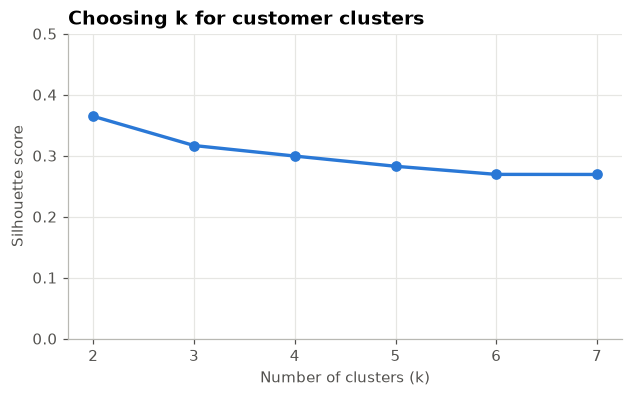

In [48]:
import textwrap
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
asof = fe.OrderDate.max() + pd.Timedelta(days=1); cf = fe[fe.Status != 'Cancelled']
rfm = cf.groupby('CustomerID').agg(recency=('OrderDate', lambda s: (asof - s.max()).days), frequency=('OrderID', 'size'), monetary=('order_value', 'sum'), avg_basket=('order_value', 'mean'), delay_rate=('IsDelayed', 'mean'), return_rate=('HasReturn', 'mean'))
nov = rfm.monetary < 500  # customers whose confirmed orders carry no line items (order-capture gap) - kept out of clustering
R['rfm_no_value_customers'] = int(nov.sum()); rfm_all = rfm.copy(); rfm = rfm[~nov].copy()
print(f'{int(nov.sum())} customers have confirmed orders but (almost) no line-item value; they are reported separately, not clustered.')
Z = StandardScaler().fit_transform(np.log1p(rfm[['recency', 'frequency', 'monetary']]))
sil = {k: silhouette_score(Z, KMeans(k, n_init=10, random_state=7).fit_predict(Z)) for k in range(2, 8)}; R['silhouette'] = {int(k): float(v) for k, v in sil.items()}
fig, ax = plt.subplots(figsize=(6.5, 3.6)); ax.plot(list(sil), list(sil.values()), color=BLUE, marker='o', lw=2.2); ax.set_title('Choosing k for customer clusters'); ax.set_xlabel('Number of clusters (k)'); ax.set_ylabel('Silhouette score'); ax.set_ylim(0, .5)
chart('25_kmeans_silhouette', 'Cluster count selection', f"Silhouette scores are modest (best {max(sil.values()):.2f} at k = {max(sil, key=sil.get)}); anything below ~0.5 signals clusters that overlap rather than form distinct groups.",
      'Customer segments here are useful as planning buckets (high/low value) but are not natural, sharply separated groups — avoid over-interpreting them.')

In [49]:
K = 4; rfm['cluster'] = KMeans(K, n_init=10, random_state=7).fit_predict(Z)
prof = rfm.groupby('cluster').agg(customers=('recency', 'size'), recency=('recency', 'mean'), frequency=('frequency', 'mean'), monetary=('monetary', 'mean'), avg_basket=('avg_basket', 'mean'), delay_rate=('delay_rate', 'mean'), return_rate=('return_rate', 'mean'))
def label(r):
    hv = r.monetary >= rfm.monetary.median(); rec = r.recency <= rfm.recency.median()
    return {(True, True): 'Champions (high value, recent)', (True, False): 'At-risk high value (lapsing)', (False, True): 'Active low value', (False, False): 'Dormant low value'}[(hv, rec)]
prof['segment'] = prof.apply(label, axis=1)
for sname in prof.segment[prof.segment.duplicated(keep=False)].unique():  # disambiguate clusters that fall in the same quadrant
    idx = prof.index[prof.segment == sname]; keep = prof.loc[idx, 'monetary'].idxmax()
    for i in idx:
        if i != keep: prof.loc[i, 'segment'] = 'Newly active (recent, mid spend)'
names = prof.segment.to_dict(); rfm['segment'] = rfm.cluster.map(names)
prof['share_of_confirmed_revenue'] = rfm.groupby('cluster').monetary.sum() / rfm_all.monetary.sum(); R['segments'] = prof.round(3).to_dict('index')
print(f'Segment labels are rule-based on cluster means vs the median cluster; {rfm.shape[0]:,} customers with ≥1 confirmed order.')
prof.round(2)

Segment labels are rule-based on cluster means vs the median cluster; 945 customers with ≥1 confirmed order.

,customers,recency,frequency,monetary,avg_basket,delay_rate,return_rate,segment,share_of_confirmed_revenue
cluster,,,,,,,,,
0,245,38.740,5.690,"25,827.310","4,635.670",0.620,0.100,"Champions (high value, recent)",0.440
1,191,94.260,1.520,"4,653.210","3,490.710",0.680,0.070,Dormant low value,0.060
2,346,85.790,3.110,"14,018.340","4,726.280",0.620,0.100,At-risk high value (lapsing),0.340
3,163,9.060,3.670,"14,539.020","4,100.060",0.670,0.100,"Newly active (recent, mid spend)",0.160


Chart 26 · Customer segments (RFM + K-Means)
  Interpretation: Champions (245 customers) average 25.8K each and hold 44% of confirmed revenue. Segments differ in recency and frequency but all share the same delay rate (≈65%).
  Business implication: Retention effort should go to the high-value customers whose last order is old (lapsing) before they are lost; every segment suffers the same delivery experience, so service reliability is a retention risk for all of them.

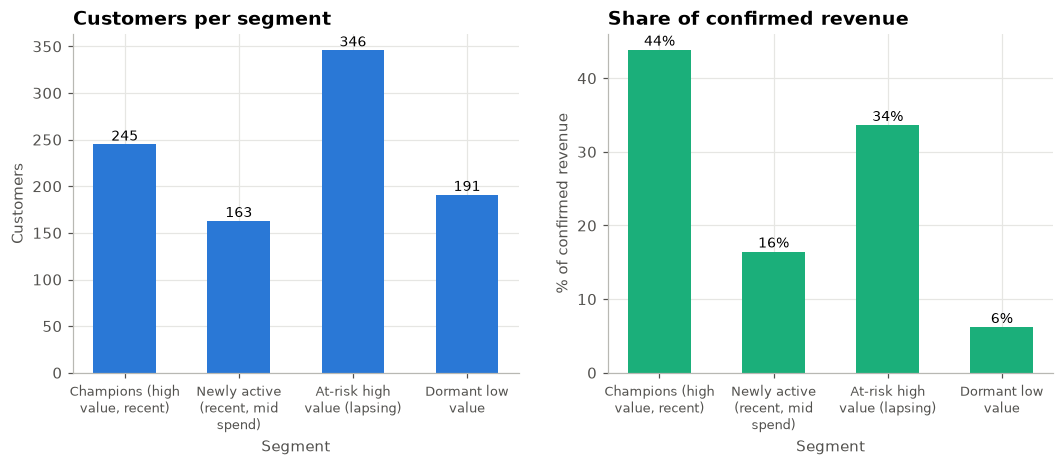

In [50]:
seg = prof.sort_values('monetary', ascending=False); seg['lab'] = [textwrap.fill(x, 16) for x in seg.segment]; fig, axs = plt.subplots(1, 2, figsize=(11.5, 4))
axs[0].bar(seg.lab, seg.customers, color=BLUE, width=.55); axs[0].set_title('Customers per segment'); axs[0].set_xlabel('Segment'); axs[0].set_ylabel('Customers'); axs[0].tick_params(axis='x', labelsize=8.5)
for i, v in enumerate(seg.customers): axs[0].text(i, v + 4, int(v), ha='center', fontsize=9)
axs[1].bar(seg.lab, seg.share_of_confirmed_revenue*100, color=AQUA, width=.55); axs[1].set_title('Share of confirmed revenue'); axs[1].set_xlabel('Segment'); axs[1].set_ylabel('% of confirmed revenue'); axs[1].tick_params(axis='x', labelsize=8.5)
for i, v in enumerate(seg.share_of_confirmed_revenue*100): axs[1].text(i, v + .6, f'{v:.0f}%', ha='center', fontsize=9)
top_seg = seg.iloc[0]
chart('26_customer_segments', 'Customer segments (RFM + K-Means)', f"{top_seg.segment.split(' (')[0]} ({int(top_seg.customers)} customers) average {short(top_seg.monetary)} each and hold {pct(top_seg.share_of_confirmed_revenue,0)} of confirmed revenue. Segments differ in recency and frequency but all share the same delay rate (≈{pct(prof.delay_rate.mean(),0)}).",
      'Retention effort should go to the high-value customers whose last order is old (lapsing) before they are lost; every segment suffers the same delivery experience, so service reliability is a retention risk for all of them.')

Chart 27 · Product ABC segmentation
  Interpretation: Class A (top 20%, 50 products) earns 36.0% of confirmed revenue; class C (bottom 50%) still earns 27.3%. All three categories appear in every class.
  Business implication: ABC differences are mild, so a tail clean-up would give up real revenue. Manage class A for availability (never stock out), and review class C on margin and return data before deleting any line.

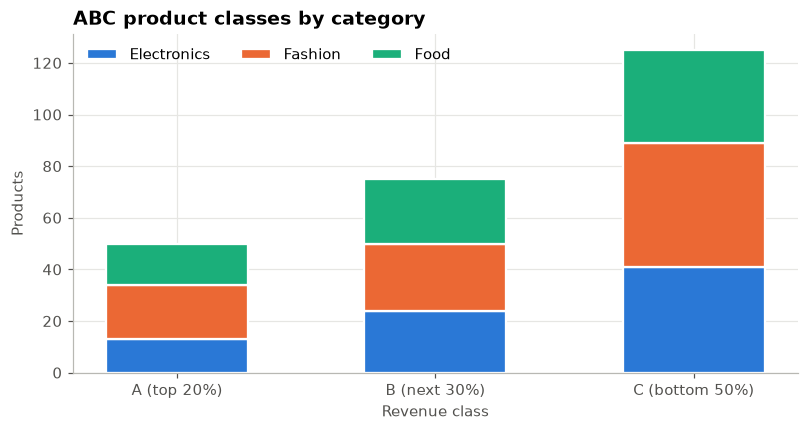

In [51]:
pa = oi_conf.groupby('ProductID').agg(revenue=('LineValue', 'sum'), units=('Quantity', 'sum'), orders=('OrderID', 'nunique')).join(cl['Products'].set_index('ProductID')[['Category', 'UnitPrice']])
rt_p = cl['Returns'].merge(cl['Order_Items'][['OrderID', 'ProductID']], on='OrderID').groupby('ProductID').size().rename('returns_touching'); pa = pa.join(rt_p).fillna({'returns_touching': 0})
pa['rev_rank_share'] = pa.revenue.rank(ascending=False) / len(pa); pa['ABC'] = np.where(pa.rev_rank_share <= .2, 'A (top 20%)', np.where(pa.rev_rank_share <= .5, 'B (next 30%)', 'C (bottom 50%)'))
abc = pa.groupby('ABC').agg(products=('revenue', 'size'), revenue=('revenue', 'sum'), units=('units', 'sum')); abc['revenue_share'] = abc.revenue / abc.revenue.sum(); R['abc'] = abc.round(3).to_dict('index')
xt = pd.crosstab(pa.ABC, pa.Category)
fig, ax = plt.subplots(figsize=(8.5, 4)); bottom = np.zeros(3); catcol = {'Electronics': BLUE, 'Fashion': ORANGE, 'Food': AQUA}
for ccat in ['Electronics', 'Fashion', 'Food']:
    ax.bar(xt.index, xt[ccat], bottom=bottom, color=catcol[ccat], label=ccat, width=.55, edgecolor='white', linewidth=1.5); bottom += xt[ccat].values
ax.set_title('ABC product classes by category'); ax.set_xlabel('Revenue class'); ax.set_ylabel('Products'); ax.legend(ncol=3, loc='upper left')
chart('27_abc_classes', 'Product ABC segmentation', f"Class A (top 20%, {int(abc.loc['A (top 20%)','products'])} products) earns {pct(abc.loc['A (top 20%)','revenue_share'])} of confirmed revenue; class C (bottom 50%) still earns {pct(abc.loc['C (bottom 50%)','revenue_share'])}. All three categories appear in every class.",
      'ABC differences are mild, so a tail clean-up would give up real revenue. Manage class A for availability (never stock out), and review class C on margin and return data before deleting any line.')

Chart 28 · Warehouse performance clusters
  Interpretation: Three warehouse clusters emerge (silhouette 0.24). Best composite reliability: W01; weakest: W15. Because delay differences are statistically insignificant, clusters are driven mostly by workload and stock risk.
  Business implication: Use the composite Reliability Score as a monitoring dashboard, not a ranking for blame. It is the best supplier-performance substitute available until supplier IDs are captured on inventory and shipments.

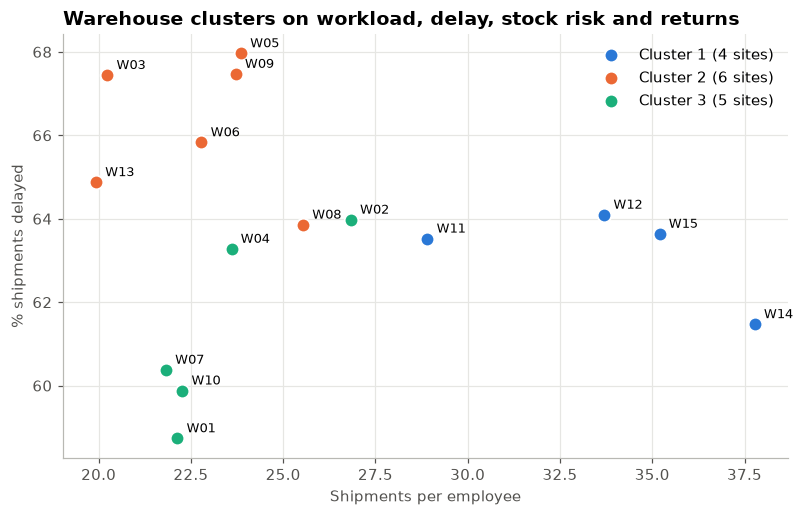

In [52]:
wk = wl[['ship_per_emp']].join(dw[['rate', 'md']]).join(wi[['low', 'stock']]); wk = wk.join(pd.DataFrame({'return_rate': master.groupby('WarehouseID').HasReturn.mean()}))
wk.columns = ['workload_per_emp', 'delay_rate', 'mean_delay', 'low_stock_positions', 'stock', 'return_rate']
Zw = StandardScaler().fit_transform(wk[['workload_per_emp', 'delay_rate', 'low_stock_positions', 'return_rate']]); wk['cluster'] = KMeans(3, n_init=20, random_state=7).fit_predict(Zw)
sw = silhouette_score(Zw, wk.cluster); R['wh_silhouette'] = float(sw)
# reliability score: z-score composite (lower delay, lower return, fewer low-stock = better)
zs = lambda s: (s - s.mean()) / s.std(); wk['reliability_score'] = -(zs(wk.delay_rate) + zs(wk.return_rate) + zs(wk.low_stock_positions)) / 3
wk['rank'] = wk.reliability_score.rank(ascending=False).astype(int); R['wh_reliability'] = wk.round(3).to_dict('index')
fig, ax = plt.subplots(figsize=(8.5, 5)); cm_ = {0: BLUE, 1: ORANGE, 2: AQUA}
for cl_, d in wk.groupby('cluster'): ax.scatter(d.workload_per_emp, d.delay_rate*100, s=80, color=cm_[cl_], label=f'Cluster {cl_ + 1} ({len(d)} sites)', edgecolor='white', lw=1.2)
for w, r in wk.iterrows(): ax.annotate(w, (r.workload_per_emp, r.delay_rate*100), xytext=(6, 4), textcoords='offset points', fontsize=8.5)
ax.set_title('Warehouse clusters on workload, delay, stock risk and returns'); ax.set_xlabel('Shipments per employee'); ax.set_ylabel('% shipments delayed'); ax.legend(loc='best')
chart('28_warehouse_clusters', 'Warehouse performance clusters', f"Three warehouse clusters emerge (silhouette {sw:.2f}). Best composite reliability: {wk.reliability_score.idxmax()}; weakest: {wk.reliability_score.idxmin()}. Because delay differences are statistically insignificant, clusters are driven mostly by workload and stock risk.",
      'Use the composite Reliability Score as a monitoring dashboard, not a ranking for blame. It is the best supplier-performance substitute available until supplier IDs are captured on inventory and shipments.')

Chart 29 · Weekday patterns
  Interpretation: Order volume is flat across weekdays (694–726 orders) and delay rates stay within 61%–65%; no weekday effect.
  Business implication: There is no peak day to staff for, and no day where delays are worse; weekly roster changes would not help. Orders also arrive every day of the week including weekends, which is unusual and worth confirming with the order system owners.
Total charts produced: 29

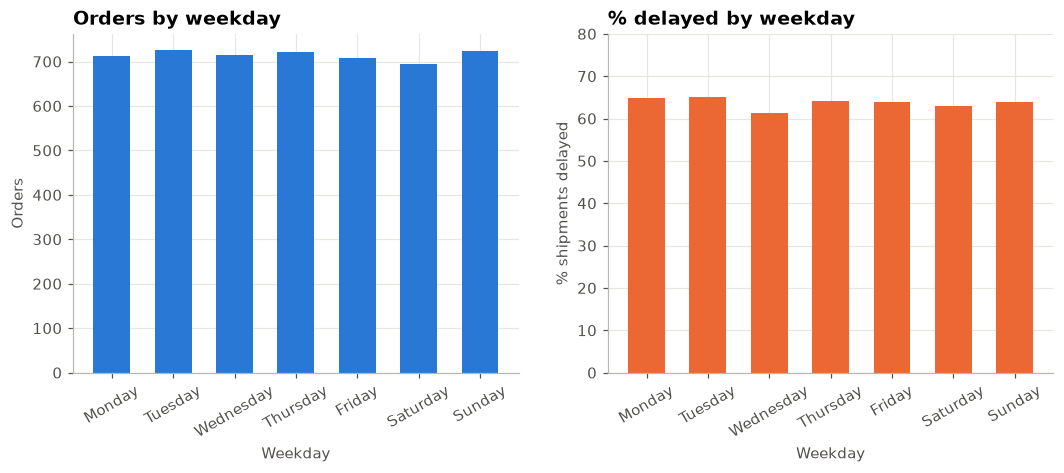

In [53]:
dom = master.groupby('DominantCategory').agg(orders=('OrderID', 'size'), delay=('IsDelayed', 'mean'), ret=('HasReturn', 'mean'), cancel=('Status', lambda s: (s == 'Cancelled').mean()), aov=('order_value', 'mean'))
dow = master.groupby('DayOfWeek').agg(orders=('OrderID', 'size'), delay=('IsDelayed', 'mean')); R['dow'] = dow.round(3).to_dict('index'); R['dom_cat'] = dom.round(3).to_dict('index')
order_d = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']; dow = dow.reindex([d for d in order_d if d in dow.index])
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4)); axs[0].bar(dow.index, dow.orders, color=BLUE, width=.6); axs[0].set_title('Orders by weekday'); axs[0].set_xlabel('Weekday'); axs[0].set_ylabel('Orders'); axs[0].tick_params(axis='x', labelrotation=30)
axs[1].bar(dow.index, dow.delay*100, color=ORANGE, width=.6); axs[1].set_title('% delayed by weekday'); axs[1].set_xlabel('Weekday'); axs[1].set_ylabel('% shipments delayed'); axs[1].set_ylim(0, 80); axs[1].tick_params(axis='x', labelrotation=30)
chart('29_weekday_patterns', 'Weekday patterns', f"Order volume is flat across weekdays ({dow.orders.min()}–{dow.orders.max()} orders) and delay rates stay within {pct(dow.delay.min(),0)}–{pct(dow.delay.max(),0)}; no weekday effect.",
      'There is no peak day to staff for, and no day where delays are worse; weekly roster changes would not help. Orders also arrive every day of the week including weekends, which is unusual and worth confirming with the order system owners.')
print(f'Total charts produced: {len(CH)}')

---
# PART 7 — Business Insights & Recommendations
Each answer cites the evidence (chart/test) it rests on. Where the data cannot answer a question, we say so and state what must be captured.

In [54]:
# Q5 evidence: product-level return rate (share of order-lines whose order had a return), with a noise check
ol = cl['Order_Items'].merge(master[['OrderID', 'HasReturn', 'Status']], on='OrderID'); pr_ = ol.groupby('ProductID').agg(lines=('OrderID', 'size'), rr=('HasReturn', 'mean')).join(cl['Products'].set_index('ProductID').Category)
pr_ = pr_[pr_.lines >= 30]; base_rr = ol.HasReturn.mean(); se = np.sqrt(base_rr * (1 - base_rr) / pr_.lines); pr_['z'] = (pr_.rr - base_rr) / se
n_out = int((pr_.z.abs() > 3).sum()); exp_out = len(pr_) * 0.0027
top_ret = pr_.sort_values('rr', ascending=False).head(5)
cat_rr = ol.merge(cl['Products'][['ProductID', 'Category']], on='ProductID', suffixes=('', '_p')).groupby('Category_p').HasReturn.mean() if 'Category' in ol else None
ctp = pd.crosstab(ol.merge(cl['Products'][['ProductID', 'Category']].rename(columns={'Category': 'Cat'}), on='ProductID').Cat, ol.HasReturn); p_cat_ret = stats.chi2_contingency(ctp)[1]
R['prod_ret_top'] = top_ret.round(3).to_dict('index'); R['prod_ret_outliers'] = n_out; R['prod_ret_expected_outliers'] = float(exp_out); R['p_cat_return'] = float(p_cat_ret); R['base_product_return_rate'] = float(base_rr)
print(f'Products with ≥30 order lines: {len(pr_)}. Highest return rate: {top_ret.index[0]} at {pct(top_ret.rr.iloc[0])} (n={int(top_ret.lines.iloc[0])} lines) vs network {pct(base_rr)}.')
print(f'Products more than 3 SE away from the network rate: {n_out} (≈{exp_out:.1f} expected by chance). Return rate by category: p = {p_cat_ret:.2f}.')
top_ret.round(3)

Products with ≥30 order lines: 250. Highest return rate: P032 at 21.3% (n=47 lines) vs network 9.5%.
Products more than 3 SE away from the network rate: 0 (≈0.7 expected by chance). Return rate by category: p = 0.96.

,lines,rr,Category,z
ProductID,,,,
P032,47,0.213,Fashion,2.763
P017,53,0.189,Fashion,2.335
P108,60,0.183,Electronics,2.343
P020,59,0.169,Food,1.961
P177,65,0.169,Electronics,2.051


In [55]:
cr = R['category_revenue']; topcat = max(cr, key=lambda k: cr[k]['revenue']); seg = R['segments']
champ = max(seg.values(), key=lambda v: v['share_of_confirmed_revenue']); atrisk = [v for v in seg.values() if v['segment'].startswith('At-risk')]
wr = R['wh_reliability']; best_w = max(wr, key=lambda k: wr[k]['reliability_score']); worst_w = min(wr, key=lambda k: wr[k]['reliability_score'])
ws_ = sorted(R['wh_load'], key=lambda k: -R['wh_load'][k]['ship_per_emp'])[:3]; lowst = R['low_stock_worst']
rd = {k: v for k, v in R['region_delay'].items() if k.startswith('Customer city')}; worst_reg = max(rd, key=lambda k: rd[k]['rate']); best_reg = min(rd, key=lambda k: rd[k]['rate'])
A = {}
A['1. Which customer segments generate the highest business value?'] = (f"{champ['segment']} — {champ['customers']:.0f} customers averaging {short(champ['monetary'])} each, {pct(champ['share_of_confirmed_revenue'],0)} of confirmed revenue. A second value pool is the lapsing high-value group ({sum(v['customers'] for v in atrisk):.0f} customers, {pct(sum(v['share_of_confirmed_revenue'] for v in atrisk),0)} of revenue, last order ≈{atrisk[0]['recency']:.0f} days ago). Revenue is not concentrated in a few accounts (top 20% of customers = {pct(R['cust_top20_share'],0)}, Gini {R['cust_gini']:.2f}). Evidence: charts 10, 11, 26.")
A['2. Which products contribute most to revenue?'] = (f"{topcat} is the top category ({pct(cr[topcat]['share'],0)} of confirmed revenue, partly because it has the most SKUs); the top products are {', '.join(p['product'] for p in R['top_products'][:3])}. But concentration is low: top 20% of products = {pct(R['top20pct_products_share'],0)} of revenue and {R['products_for_80']} of 250 products are needed for 80%. Rankings also shift with the status filter (only {R['top10_overlap_conf_vs_delivered']}/10 top products are the same on delivered-only revenue). Evidence: charts 12, 13, 27.")
A['3. Which suppliers consistently underperform?'] = ("This cannot be answered. The Suppliers table lists 150 IDs and names only; no SupplierID exists on Products, Inventory, Shipments or Orders, so no delivery, quality or return outcome can be traced to a supplier. We did not fabricate a link. Substitute: warehouse reliability score (chart 28). Fix: add SupplierID to Products/Inventory receipts and capture PO promised vs received dates.")
A['4. Which warehouses require operational improvements?'] = (f"Delay differences between warehouses are not statistically significant (χ² p = {R['p_delay_wh']:.2f}), so no warehouse can be blamed for delays. The operational gaps are staffing and stock: highest shipments per employee are {', '.join(ws_)} (up to {R['wh_load'][ws_[0]]['ship_per_emp']:.0f} vs {min(v['ship_per_emp'] for v in R['wh_load'].values()):.0f}), and low-stock positions cluster in {', '.join(lowst)}. Composite reliability: best {best_w}, weakest {worst_w}. Evidence: charts 8, 14, 15, 22, 28.")
A['5. Which products have the highest return rates?'] = (f"Highest observed: {', '.join(top_ret.index[:3])} (up to {pct(top_ret.rr.iloc[0])} vs {pct(base_rr)} overall), but with ~{pr_.lines.median():.0f} lines per product this is mostly noise: {n_out} products exceed ±3 SE (≈{exp_out:.1f} expected by chance) and category does not matter (p = {p_cat_ret:.2f}). Reason mix: {', '.join(f'{k} {v}' for k, v in R['return_reasons'].items())}. No product should be delisted on return rate alone. Evidence: chart 7.")
A['6. Which regions experience the greatest delivery delays?'] = (f"{worst_reg.split('|')[1]} has the highest delay rate ({pct(rd[worst_reg]['rate'])}) and {best_reg.split('|')[1]} the lowest ({pct(rd[best_reg]['rate'])}), but the difference is not significant (p = {R['p_delay_custcity']:.2f}). Honest answer: no region is reliably worse; the network average is {pct(R['delay_rate'])}. Evidence: charts 17, 21.")
A['7. What operational bottlenecks have you identified?'] = (f"(1) Network-wide lateness: {pct(R['delay_rate'])} of shipments are ≥3 days late and delay is uniform 0–7 days. (2) Order conversion: only {pct(R['delivered_rate'])} of orders are Delivered; {pct(R['cancel_rate'])} Cancelled ({short(R['cancelled_value'])}) and {pct(R['pending_rate'])} still Pending. (3) Process integrity: {R['ship_on_cancelled']:,} shipments are recorded against Cancelled orders. (4) Staffing imbalance ({R['load_ratio']:.1f}× workload spread). (5) Order-capture gaps: {R['orders_no_items']} orders without line items. Evidence: charts 3, 6, 8, 23.")
A['8. Which variables are most suitable for predictive modelling?'] = (f"Candidate targets: IsDelayed, DelayDays, HasReturn. Engineered features (customer history, warehouse rolling delay, load, basket) were tested, but the best time-split AUC was {R['best_auc_delay']:.2f} for delay and {R['best_auc_return']:.2f} for returns — essentially chance; {R['feature_screen_nsig']} of 24 features pass p<0.05 (≈2 by chance). So current variables are NOT suitable for delay/return prediction. Revenue, order volume and customer recency/frequency are the modelling-ready quantities (forecasting, churn). Evidence: chart 24.")
A['9. What hidden patterns did your analysis uncover?'] = (f"(a) Statuses do not drive outcomes: Cancelled and Pending orders have the same delay/return rates as Delivered ones, implying the status field and shipment/return events are out of sync. (b) 'Late Delivery' returns are no more likely to be actually delayed ({pct(R['late_reason_delayed_share'],0)}) than any other return. (c) Delay is unrelated to value, basket, route, weekday or returns (max |ρ| {R['max_nonstructural_corr']:.2f}). (d) Revenue is flat across Jan–Aug with no growth trend. (e) Ibadan has the largest customer base but no warehouse. Evidence: charts 18, 20, 23.")
for k, v in A.items(): print(k, '\n   ', v, '\n')
R['answers'] = A

1. Which customer segments generate the highest business value? 
    Champions (high value, recent) — 245 customers averaging 25.8K each, 44% of confirmed revenue. A second value pool is the lapsing high-value group (346 customers, 34% of revenue, last order ≈86 days ago). Revenue is not concentrated in a few accounts (top 20% of customers = 41%, Gini 0.38). Evidence: charts 10, 11, 26. 

2. Which products contribute most to revenue? 
    Fashion is the top category (38% of confirmed revenue, partly because it has the most SKUs); the top products are P085, P040, P025. But concentration is low: top 20% of products = 36% of revenue and 145 of 250 products are needed for 80%. Rankings also shift with the status filter (only 6/10 top products are the same on delivered-only revenue). Evidence: charts 12, 13, 27. 

3. Which suppliers consistently underperform? 
    This cannot be answered. The Suppliers table lists 150 IDs and names only; no SupplierID exists on Products, Inventory, Shipment

In [56]:
recs = [
 ('Reconcile order status with shipment and return events', 'Data / Process', f"{R['ship_on_cancelled']:,} shipments and 161 returns sit on Cancelled orders; delay KPIs are contaminated", 'High', 'Trusted KPIs; prerequisite for any ML'),
 ('Launch a network-wide on-time delivery programme (carrier SLAs, dispatch cut-offs, promise-date review)', 'Operations', f"{pct(R['delay_rate'])} late, uniform across sites/regions — a systemic cause", 'High', 'Each 10-point cut in lateness lifts on-time rate to ~46%'),
 ('Attack the cancellation/pending leak with a funnel review (stock confirmation, payment, address checks)', 'Commercial', f"{pct(R['cancel_rate'])} cancelled, {short(R['cancelled_value'])} order value; only {pct(R['delivered_rate'])} delivered", 'High', 'Recovering 10% of cancelled value ≈ ' + short(R['cancelled_value'] * .1)),
 ('Rebalance warehouse staffing toward overloaded sites (' + ', '.join(ws_) + ')', 'Operations', f"{R['load_ratio']:.1f}× spread in shipments per employee with near-equal volumes", 'Medium', 'Better utilisation without extra headcount'),
 ('Targeted replenishment at low-stock hotspots (' + ', '.join(lowst) + ')', 'Inventory', f"{R['low_stock_positions']} positions below {LOW_STOCK} units, concentrated in few sites", 'Medium', 'Fewer stock-outs without raising total stock'),
 ('Win-back programme for lapsing high-value customers', 'Customer', f"{sum(v['customers'] for v in atrisk):.0f} customers, {pct(sum(v['share_of_confirmed_revenue'] for v in atrisk),0)} of revenue, ≈{atrisk[0]['recency']:.0f} days since last order", 'High', 'Protects about a third of confirmed revenue'),
 ('Introduce a loyalty/frequency scheme across the whole base rather than key-account management', 'Customer', f"Top 20% of customers = {pct(R['cust_top20_share'],0)} of revenue (Gini {R['cust_gini']:.2f}); no whales", 'Medium', 'Raises orders per customer (now ' + f"{R['orders_per_cust_mean']:.1f})"),
 ('Assess an Ibadan fulfilment point', 'Network', 'Largest customer city (26%) with no warehouse; all Ibadan orders ship cross-city', 'Medium', 'Possible shorter lead times; needs cost-benefit (distance data not available)'),
 ('Capture the missing data: SupplierID, carrier, promised/dispatch/delivery dates, warehouse capacity, return product', 'Data', 'Supplier performance, capacity utilisation and ML are impossible today', 'High', 'Unlocks supplier scorecards and delay prediction'),
 ('Fix order capture: block orders without line items and fix the empty-basket cohort', 'Data / Process', f"{R['orders_no_items']} orders ({pct(R['orders_no_items']/5000)}) have no items; {R['rfm_no_value_customers']} customers with no valued orders", 'Medium', 'Complete revenue visibility'),
 ('Replace free-text return reasons with a controlled pick-list and audit "Late Delivery" coding', 'Quality', f"Only {pct(R['late_reason_delayed_share'],0)} of 'Late Delivery' returns were delayed shipments", 'Medium', 'Reliable root-cause for returns'),
 ('Tackle controllable returns (wrong item, damaged) through pick-accuracy checks and packaging', 'Quality', f"Wrong Item + Damaged = {pct((R['return_reasons']['Wrong Item']+R['return_reasons']['Damaged'])/sum(R['return_reasons'].values()),0)} of returns; {pct(R['return_rate'])} of orders affected", 'Medium', 'Lower return handling cost'),
 ('Manage the range by revenue per SKU and margin, not total revenue; do not cut the tail yet', 'Merchandising', f"{R['products_for_80']} of 250 products needed for 80% of revenue; class C still earns {pct(R['abc']['C (bottom 50%)']['revenue_share'],0)}", 'Low', 'Avoids losing tail revenue'),
 ('Monitor delays with control charts at region level, not warehouse/lane league tables', 'Analytics', f"Lane samples ≈{R['route_cell_n_median']:.0f} shipments; most spread is noise", 'Low', 'Avoids acting on noise'),
 ('Build future ML (delay-risk scoring, demand forecast, churn) only after new data fields exist', 'Analytics', f"Current best AUC {R['best_auc_delay']:.2f}", 'Medium', 'Avoids deploying a useless model'),
]
RC = pd.DataFrame(recs, columns=['recommendation', 'area', 'evidence', 'priority', 'expected_impact']); RC.index = RC.index + 1; R['recommendations'] = RC.reset_index().to_dict('records')
A['10. What recommendations would you make to improve SwiftLog\'s operations?'] = f"{len(RC)} prioritised recommendations — see table below; top priorities: status reconciliation, network-wide on-time programme, cancellation funnel, data capture, win-back."
R['answers'] = A
print(f'{len(RC)} strategic recommendations (brief requires ≥10).')
RC

15 strategic recommendations (brief requires ≥10).

,recommendation,area,evidence,priority,expected_impact
1,Reconcile order status with shipment and return events,Data / Process,"1,626 shipments and 161 returns sit on Cancelled orders; delay KPIs are contaminated",High,Trusted KPIs; prerequisite for any ML
2,"Launch a network-wide on-time delivery programme (carrier SLAs, dispatch cut-offs, promise-date review)",Operations,"63.7% late, uniform across sites/regions — a systemic cause",High,Each 10-point cut in lateness lifts on-time rate to ~46%
3,"Attack the cancellation/pending leak with a funnel review (stock confirmation, payment, address checks)",Commercial,"32.5% cancelled, 7.23M order value; only 33.2% delivered",High,Recovering 10% of cancelled value ≈ 722.9K
4,"Rebalance warehouse staffing toward overloaded sites (W14, W15, W12)",Operations,1.9× spread in shipments per employee with near-equal volumes,Medium,Better utilisation without extra headcount
5,"Targeted replenishment at low-stock hotspots (W14, W06, W13)",Inventory,"54 positions below 20 units, concentrated in few sites",Medium,Fewer stock-outs without raising total stock
6,Win-back programme for lapsing high-value customers,Customer,"346 customers, 34% of revenue, ≈86 days since last order",High,Protects about a third of confirmed revenue
7,Introduce a loyalty/frequency scheme across the whole base rather than key-account management,Customer,Top 20% of customers = 41% of revenue (Gini 0.38); no whales,Medium,Raises orders per customer (now 5.0)
8,Assess an Ibadan fulfilment point,Network,Largest customer city (26%) with no warehouse; all Ibadan orders ship cross-city,Medium,Possible shorter lead times; needs cost-benefit (distance data not available)
9,"Capture the missing data: SupplierID, carrier, promised/dispatch/delivery dates, warehouse capacity, return product",Data,"Supplier performance, capacity utilisation and ML are impossible today",High,Unlocks supplier scorecards and delay prediction
10,Fix order capture: block orders without line items and fix the empty-basket cohort,Data / Process,236 orders (4.7%) have no items; 14 customers with no valued orders,Medium,Complete revenue visibility


In [57]:
lim = ['Order dates cover 1 Jan – 8 Sep 2026; September is partial.', 'No currency, cost, margin, supplier link, carrier, capacity or ship/delivery dates in the data; revenue is order value from unit price × quantity.',
       'Order status is inconsistent with shipments/returns, so "realised" revenue is a conservative lower bound.', 'The synthetic-looking uniformity of delay, returns and values limits predictive and segmentation power; tests are many, so only Bonferroni-surviving findings should drive investment (none did).',
       'Warehouse capacity is unknown, so workload per employee is a proxy not utilisation.']
R['limitations'] = lim
for l in lim: print('•', l)
print(f'\nFinal chart count: {len(CH)}')

• Order dates cover 1 Jan – 8 Sep 2026; September is partial.
• No currency, cost, margin, supplier link, carrier, capacity or ship/delivery dates in the data; revenue is order value from unit price × quantity.
• Order status is inconsistent with shipments/returns, so "realised" revenue is a conservative lower bound.
• The synthetic-looking uniformity of delay, returns and values limits predictive and segmentation power; tests are many, so only Bonferroni-surviving findings should drive investment (none did).
• Warehouse capacity is unknown, so workload per employee is a proxy not utilisation.

Final chart count: 29